<h4>220014792 - ID5059 Coursework 1
<h1>Flight Delays

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import math

<h2>1.0 Read in data

In [2]:
# Read in the datasets
df_airports_orig = pd.read_csv('airports.csv')
df_flights_orig = pd.read_csv('flights.csv')
df_weather_orig = pd.read_csv('weather.csv')
df_planes_orig = pd.read_csv('planes.csv')
df_airlines_orig = pd.read_csv('airlines.csv')

# Make copies to leave original data untouched
df_airports = df_airports_orig.copy()
df_flights = df_flights_orig.copy()
df_weather = df_weather_orig.copy()
df_planes = df_planes_orig.copy()
df_airlines = df_airlines_orig.copy()

<h2> 2.0 Investigate missing data

In [3]:
# Print the total number of missing values in each dataframe
print('Missing data in flights')
print((df_flights.isna().sum(axis=0)*100/df_flights.shape[0]).round(4))
print('Missing data in airports')
print((df_airports.isna().sum(axis=0)*100/df_flights.shape[0]).round(4))
print('Missing data in airlines')
print((df_airlines.isna().sum(axis=0)*100/df_flights.shape[0]).round(4))
print('Missing data in weather')
print((df_weather.isna().sum(axis=0)*100/df_flights.shape[0]).round(4))
print('Missing data in planes')
print((df_planes.isna().sum(axis=0)*100/df_flights.shape[0]).round(4))
# Clearly, there is an issue in "df_flights", with many missing values in several columns.
# We will have to deal with this later.

Missing data in flights
year              0.0000
month             0.0000
day               0.0000
dep_time          2.4512
sched_dep_time    0.0000
dep_delay         2.4512
arr_time          2.5872
sched_arr_time    0.0000
arr_delay         2.8001
carrier           0.0000
flight            0.0000
tailnum           0.7459
origin            0.0000
dest              0.0000
air_time          2.8001
distance          0.0000
hour              0.0000
minute            0.0000
time_hour         0.0000
dtype: float64
Missing data in airports
faa      0.0000
name     0.0000
lat      0.0000
lon      0.0000
alt      0.0000
tz       0.0000
dst      0.0000
tzone    0.0009
dtype: float64
Missing data in airlines
carrier    0.0
name       0.0
dtype: float64
Missing data in weather
origin        0.0000
year          0.0000
month         0.0000
day           0.0000
hour          0.0000
temp          0.0003
dewp          0.0003
humid         0.0003
wind_dir      0.1366
wind_speed    0.0012
wind_gust     

In [4]:
# Define a function to find Non-numeric entries in a specified column
def find_Non_numeric_entries(series):
    Non_numeric = series[pd.to_numeric(series, errors="coerce").isna()].unique()
    return Non_numeric

# Print Non-numeric entries in each of the numeric columns of each dataframe
print('Non-numeric entries in flights')
print(find_Non_numeric_entries(df_flights['year']))
print(find_Non_numeric_entries(df_flights['month']))
print(find_Non_numeric_entries(df_flights['day']))
print(find_Non_numeric_entries(df_flights['dep_time']))
print(find_Non_numeric_entries(df_flights['sched_dep_time']))
print(find_Non_numeric_entries(df_flights['dep_delay']))
print(find_Non_numeric_entries(df_flights['arr_time']))
print(find_Non_numeric_entries(df_flights['sched_arr_time']))
print(find_Non_numeric_entries(df_flights['arr_delay']))
print(find_Non_numeric_entries(df_flights['air_time']))
print(find_Non_numeric_entries(df_flights['distance']))
print('Non-numeric entries in airports')
print(find_Non_numeric_entries(df_airports['lat']))
print(find_Non_numeric_entries(df_airports['lon']))
print('Non-numeric entries in weather')
print(find_Non_numeric_entries(df_weather['year']))
print(find_Non_numeric_entries(df_weather['month']))
print(find_Non_numeric_entries(df_weather['day']))
print(find_Non_numeric_entries(df_weather['hour']))
print(find_Non_numeric_entries(df_weather['temp']))
print(find_Non_numeric_entries(df_weather['dewp']))
print(find_Non_numeric_entries(df_weather['humid']))
print(find_Non_numeric_entries(df_weather['wind_dir']))
print(find_Non_numeric_entries(df_weather['wind_speed']))
print(find_Non_numeric_entries(df_weather['wind_gust']))
print(find_Non_numeric_entries(df_weather['precip']))
print(find_Non_numeric_entries(df_weather['pressure']))
print(find_Non_numeric_entries(df_weather['visib']))
print('Non-numeric entries in planes')
print(find_Non_numeric_entries(df_planes['year']))
print(find_Non_numeric_entries(df_planes['engines']))
print(find_Non_numeric_entries(df_planes['seats']))
print(find_Non_numeric_entries(df_planes['speed']))


Non-numeric entries in flights
[]
[]
[]
[nan]
[]
[nan]
[nan]
[]
[nan]
[nan]
[]
Non-numeric entries in airports
[]
[]
Non-numeric entries in weather
[]
[]
[]
[]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[]
[nan]
[]
Non-numeric entries in planes
[nan]
[]
[]
[nan]


<h3>There is some missing data, but No unexpected Non-numerical values. Will be dealt with later.

<h2> 2.1 Check flights data

In [5]:
# Inspect the data types within the flights dataframe
print(df_flights.dtypes)

year                int64
month               int64
day                 int64
dep_time          float64
sched_dep_time      int64
dep_delay         float64
arr_time          float64
sched_arr_time      int64
arr_delay         float64
carrier            object
flight              int64
tailnum            object
origin             object
dest               object
air_time          float64
distance            int64
hour                int64
minute              int64
time_hour          object
dtype: object


In [6]:
# Define column that must be converted to numeric
numeric_cols = [
    "dep_time", "sched_dep_time",
    "dep_delay",
    "arr_time", "sched_arr_time",
    "arr_delay",
    "flight",
    "air_time",
    "distance",
    "hour", "minute"
]

# Loop through each of the columns and convert to numeric, coercing errors to NaN
for col in numeric_cols:
    df_flights[col] = pd.to_numeric(df_flights[col], errors="coerce")

# Convert 'time_hour' to datetime format
df_flights["time_hour"] = pd.to_datetime(df_flights["time_hour"], errors="coerce")

# Define columns that must be converted to categorical or string types
cat_cols = ["carrier", "origin", "dest"]

# Loop through columns and convert to categorical type
for col in cat_cols:
    df_flights[col] = df_flights[col].astype("category")

# Convert 'tailnum' to string type
df_flights["tailnum"] = df_flights["tailnum"].astype("string")

In [7]:
# Reinspect the data types within the flights dataframe
print(df_flights.dtypes)

year                       int64
month                      int64
day                        int64
dep_time                 float64
sched_dep_time             int64
dep_delay                float64
arr_time                 float64
sched_arr_time             int64
arr_delay                float64
carrier                 category
flight                     int64
tailnum           string[python]
origin                  category
dest                    category
air_time                 float64
distance                   int64
hour                       int64
minute                     int64
time_hour         datetime64[ns]
dtype: object


In [8]:
# Find all 'faa' values that are in both df_flights['origin'] and df_airports['faa']
common_faa = set(df_flights['origin']).intersection(set(df_airports['faa']))
print('FAA codes in df_flights that are also in df_airports:', common_faa)

# Print the corresponding timezones for the common FAA codes
print('Timezones for the common FAA codes:')
print(df_airports[df_airports['faa'].isin(common_faa)][['faa', 'tz']])
# We conclude that only a single timezone is necessary for all of the flights data.

FAA codes in df_flights that are also in df_airports: {'EWR', 'JFK', 'LGA'}
Timezones for the common FAA codes:
     faa  tz
460  EWR  -5
691  JFK  -5
786  LGA  -5


<h3>Observe that all of the flight are from 1 of 3 airports and all have the same timezone. We need Not worry about timezones.

<h2>2.2 Check airlines data

In [9]:
# Inspect the data types within the airlines dataframe
print(df_airlines.dtypes)

carrier    object
name       object
dtype: object


In [10]:
# Change both columns to strings
df_airlines["carrier"] = df_airlines["carrier"].astype("string")
df_airlines["name"] = df_airlines["name"].astype("string")

<h2>2.3 Check airports data

In [11]:
# Inspect the data types within the airport dataframe
print(df_airports.dtypes)

faa       object
name      object
lat      float64
lon      float64
alt        int64
tz         int64
dst       object
tzone     object
dtype: object


In [12]:
# Change both columns to strings
df_airports["faa"] = df_airports["faa"].astype("string")
df_airports["name"] = df_airports["name"].astype("string")

# Change these columns to categorical types
df_airports["dst"] = df_airports["dst"].astype("category")
df_airports["tzone"] = df_airports["tzone"].astype("category")

<h2>2.4 Check planes data

In [13]:
# Inspoect the data types within the planes dataframe
print(df_planes.dtypes)

tailnum          object
year            float64
type             object
manufacturer     object
model            object
engines           int64
seats             int64
speed           float64
engine           object
dtype: object


In [14]:
# Convert 'tailnum' to string type
df_planes["tailnum"] = df_planes["tailnum"].astype("string")

#Convert types to categorical
df_planes["type"] = df_planes["type"].astype("category")
df_planes["manufacturer"] = df_planes["manufacturer"].astype("category")
df_planes["model"] = df_planes["model"].astype("category")
df_planes["engine"] = df_planes["engine"].astype("category")

In [15]:
# Rename 'year' to plane_age to avoid confusion
df_planes = df_planes.rename(columns={'year': 'age_plane'})
# Add _plane suffix to each of the other columns except plane_age and tailnum (as this is the primary key for planes and will be used to merge with flights)
df_planes = df_planes.rename(columns={col: col + '_plane' for col in df_planes.columns if col not in ['age_plane', 'tailnum']})

<h2>2.5 Check weather data

In [16]:
# Inspect the data types within the weather dataframe
print(df_weather.dtypes)

origin         object
year            int64
month           int64
day             int64
hour            int64
temp          float64
dewp          float64
humid         float64
wind_dir      float64
wind_speed    float64
wind_gust     float64
precip        float64
pressure      float64
visib         float64
time_hour      object
dtype: object


In [17]:
# Convert 'time_hour' to datetime format
df_weather["time_hour"] = pd.to_datetime(df_weather["time_hour"], errors="coerce")

# Change origin to categorical type
df_weather["origin"] = df_weather["origin"].astype("category")

In [18]:
# Reinspect the data types within the weather dataframe
print(df_weather.dtypes)

origin                   category
year                        int64
month                       int64
day                         int64
hour                        int64
temp                      float64
dewp                      float64
humid                     float64
wind_dir                  float64
wind_speed                float64
wind_gust                 float64
precip                    float64
pressure                  float64
visib                     float64
time_hour     datetime64[ns, UTC]
dtype: object


In [19]:
# Print unique values in the 'origin' column of the weather dataframe
print(df_weather['origin'].unique())

['EWR', 'JFK', 'LGA']
Categories (3, object): ['EWR', 'JFK', 'LGA']


In [20]:
# These unique values match those in the origin column of the flights dataframe. We can therefore remove the time zone information.
# Convert weather time_hour to the same timezone as the flights data (UTC-5)
df_weather['time_hour'] = df_weather['time_hour'].dt.tz_convert('America/New_York')

In [21]:
# Reinspect the data types within the weather dataframe
print(df_weather.dtypes)

origin                                category
year                                     int64
month                                    int64
day                                      int64
hour                                     int64
temp                                   float64
dewp                                   float64
humid                                  float64
wind_dir                               float64
wind_speed                             float64
wind_gust                              float64
precip                                 float64
pressure                               float64
visib                                  float64
time_hour     datetime64[ns, America/New_York]
dtype: object


In [22]:
# Check for unrealistic values
df_weather['wind_speed'].max()

1048.36058

<h3>We have thus dealt with the difference in timezones, by localising the weather date_time

<h2>3.0 Change date_time in flights to type: America/New_York

In [23]:
# Inspect the data types within the flights dataframe
df_flights['time_hour'] = df_flights['time_hour'].dt.tz_localize('America/New_York', ambiguous='NaT', nonexistent='NaT')

# Inspect the data types within the flights dataframe
print(df_flights.dtypes)

year                                         int64
month                                        int64
day                                          int64
dep_time                                   float64
sched_dep_time                               int64
dep_delay                                  float64
arr_time                                   float64
sched_arr_time                               int64
arr_delay                                  float64
carrier                                   category
flight                                       int64
tailnum                             string[python]
origin                                    category
dest                                      category
air_time                                   float64
distance                                     int64
hour                                         int64
minute                                       int64
time_hour         datetime64[ns, America/New_York]
dtype: object


<h2>3.1 Create a super table by merging the datasets

In [24]:
# Remove day, hour, month column from weather as they are in flights too.
df_weather = df_weather.drop(columns=['day', 'hour', 'month'])

# Merge weather into flights
df = pd.merge(df_flights, df_weather, left_on=['origin', 'time_hour'], right_on=['origin', 'time_hour'], how='left')

In [25]:
# Remove tz from airports as it is singular in flights
df_airports = df_airports.drop(columns=['tz'])

# Merge airports into df
df = pd.merge(df, df_airports, left_on='origin', right_on='faa', how='left', suffixes=('', '_origin'))

In [26]:
# Merge planes into df
df = pd.merge(df, df_planes, left_on='tailnum', right_on='tailnum', how='left', suffixes=('', '_plane'))

In [27]:
print(df.columns)

Index(['year_x', 'month', 'day', 'dep_time', 'sched_dep_time', 'dep_delay',
       'arr_time', 'sched_arr_time', 'arr_delay', 'carrier', 'flight',
       'tailnum', 'origin', 'dest', 'air_time', 'distance', 'hour', 'minute',
       'time_hour', 'year_y', 'temp', 'dewp', 'humid', 'wind_dir',
       'wind_speed', 'wind_gust', 'precip', 'pressure', 'visib', 'faa', 'name',
       'lat', 'lon', 'alt', 'dst', 'tzone', 'age_plane', 'type_plane',
       'manufacturer_plane', 'model_plane', 'engines_plane', 'seats_plane',
       'speed_plane', 'engine_plane'],
      dtype='object')


In [28]:
print('Missing data in df')
print((df.isna().sum(axis=0)*100/df.shape[0]).round(4))

Missing data in df
year_x                 0.0000
month                  0.0000
day                    0.0000
dep_time               2.4512
sched_dep_time         0.0000
dep_delay              2.4512
arr_time               2.5872
sched_arr_time         0.0000
arr_delay              2.8001
carrier                0.0000
flight                 0.0000
tailnum                0.7459
origin                 0.0000
dest                   0.0000
air_time               2.8001
distance               0.0000
hour                   0.0000
minute                 0.0000
time_hour              0.0000
year_y                 0.4620
temp                   0.4671
dewp                   0.4671
humid                  0.4671
wind_dir               2.9088
wind_speed             0.4852
wind_gust             76.1310
precip                 0.4620
pressure              11.5174
visib                  0.4620
faa                    0.0000
name                   0.0000
lat                    0.0000
lon                  

In [29]:
# Print the number of unique values in each column of df
print(df.nunique())

year_x                   1
month                   12
day                     31
dep_time              1318
sched_dep_time        1021
dep_delay              527
arr_time              1411
sched_arr_time        1163
arr_delay              577
carrier                 16
flight                3844
tailnum               4043
origin                   3
dest                   105
air_time               509
distance               214
hour                    20
minute                  60
time_hour             6936
year_y                   1
temp                   168
dewp                   147
humid                 2442
wind_dir                37
wind_speed              34
wind_gust               35
precip                  55
pressure               454
visib                   20
faa                      3
name                     3
lat                      3
lon                      3
alt                      3
dst                      1
tzone                    1
age_plane               46
t

<h2>4.0 Refining the dataset

In [30]:
# Removing rows

# Remove rows with singular values
df = df.drop(columns=['dst', 'tzone', 'year_x', 'year_y'])

# Remove rows with more than 50% missing values
df = df.drop(columns=['wind_gust', 'speed_plane'])

# The task also asks for a prediction of latency prior to a flight taking off. We thus remove all attributes that are Not kNown prior to takeoff.
after_takeoff_cols = ['arr_time', 'air_time', 'dep_time', 'dep_delay']
df = df.drop(columns=after_takeoff_cols)

# Remove duplicate rows after the merges
df = df.drop(columns=['faa', 'name'])

# Remove unique identifiers that will Not generalise well in a model
# We choose to remove 'tailnum' because it is likely that an aircraft will Not be in the set. It is therefore Not useful for a model to learn patterns based on this variable.
df = df.drop(columns=['tailnum', 'flight'])

print(df.dtypes)


month                                            int64
day                                              int64
sched_dep_time                                   int64
sched_arr_time                                   int64
arr_delay                                      float64
carrier                                       category
origin                                          object
dest                                          category
distance                                         int64
hour                                             int64
minute                                           int64
time_hour             datetime64[ns, America/New_York]
temp                                           float64
dewp                                           float64
humid                                          float64
wind_dir                                       float64
wind_speed                                     float64
precip                                         float64
pressure  

<h2>4.1 Assess with missing data

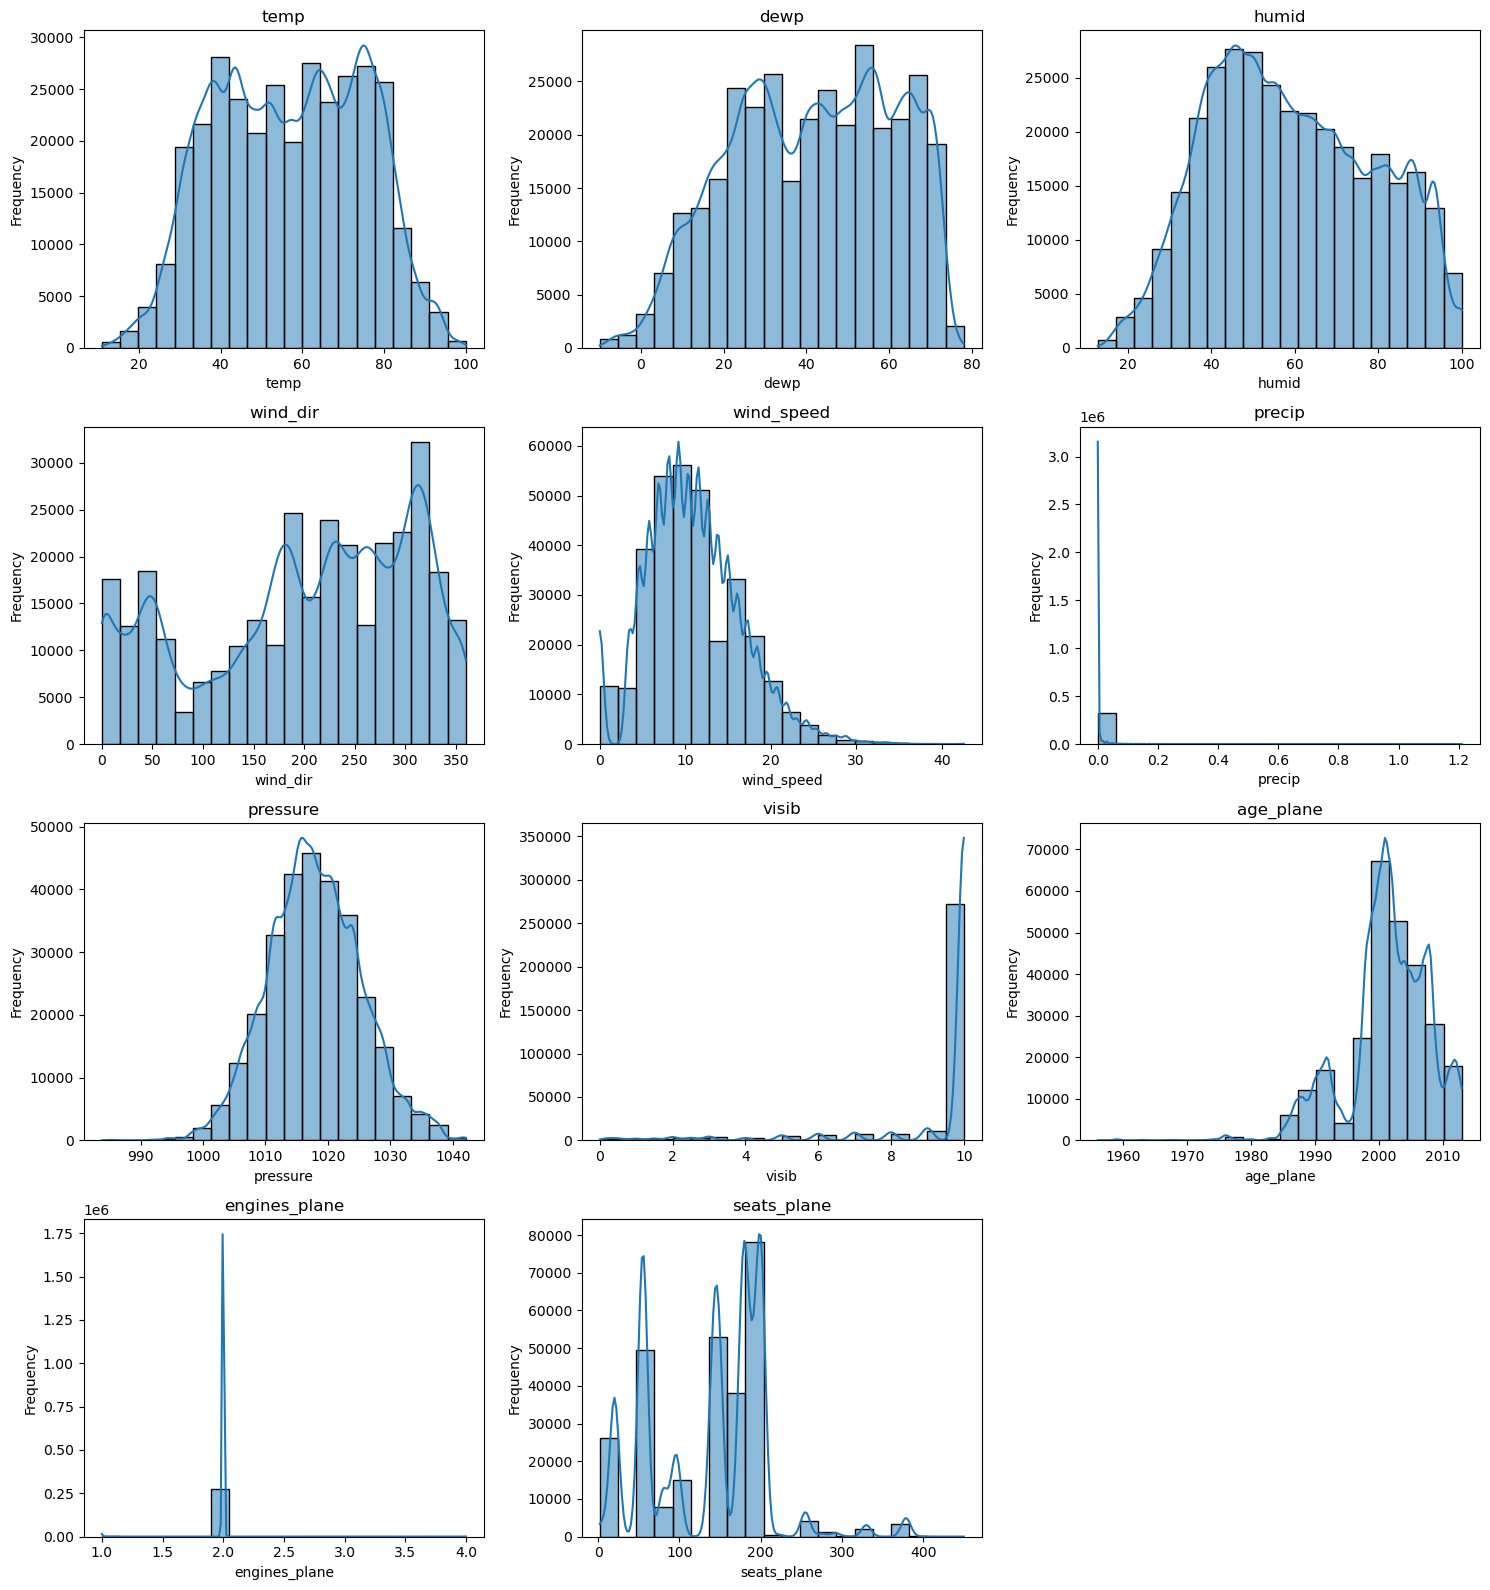

In [31]:
# Delete rows with missing values in 'arr_delay' (the target variable)
df = df.dropna(subset=['arr_delay'])

# First address numeric columns with missing values
# We plot each of the distributions to determine whether imputation is appropriate.
num_df = df.select_dtypes(include="number")

cols_with_missing = num_df.columns[num_df.isna().any()].tolist()

n_cols = 3
n_rows = math.ceil(len(cols_with_missing) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(5 * n_cols, 4 * n_rows)
)
axes = axes.flatten()

for ax, col in zip(axes, cols_with_missing):
    sns.histplot(
        df[col],
        bins=20,
        kde=True,
        ax=ax
    )
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

# Get rid of unused axes
for ax in axes[len(cols_with_missing):]:
    ax.axis("off")

plt.tight_layout()
plt.show()



<h3>Each of the histograms represents a, roughly, unimodal distribution, with the exception of 'seats_plane'. As a result, we choose to impute values for all columns except 'seats_plane'. Since it is missing around 15% of data, and inputation is difficult, we choose to remove the column. Additionally, the number of seats is somewhat represented in the 'model' column.

In [32]:
# Remove the seats_plane column
df = df.drop(columns=['seats_plane'])

<h2>4.2 Reviewing outliers

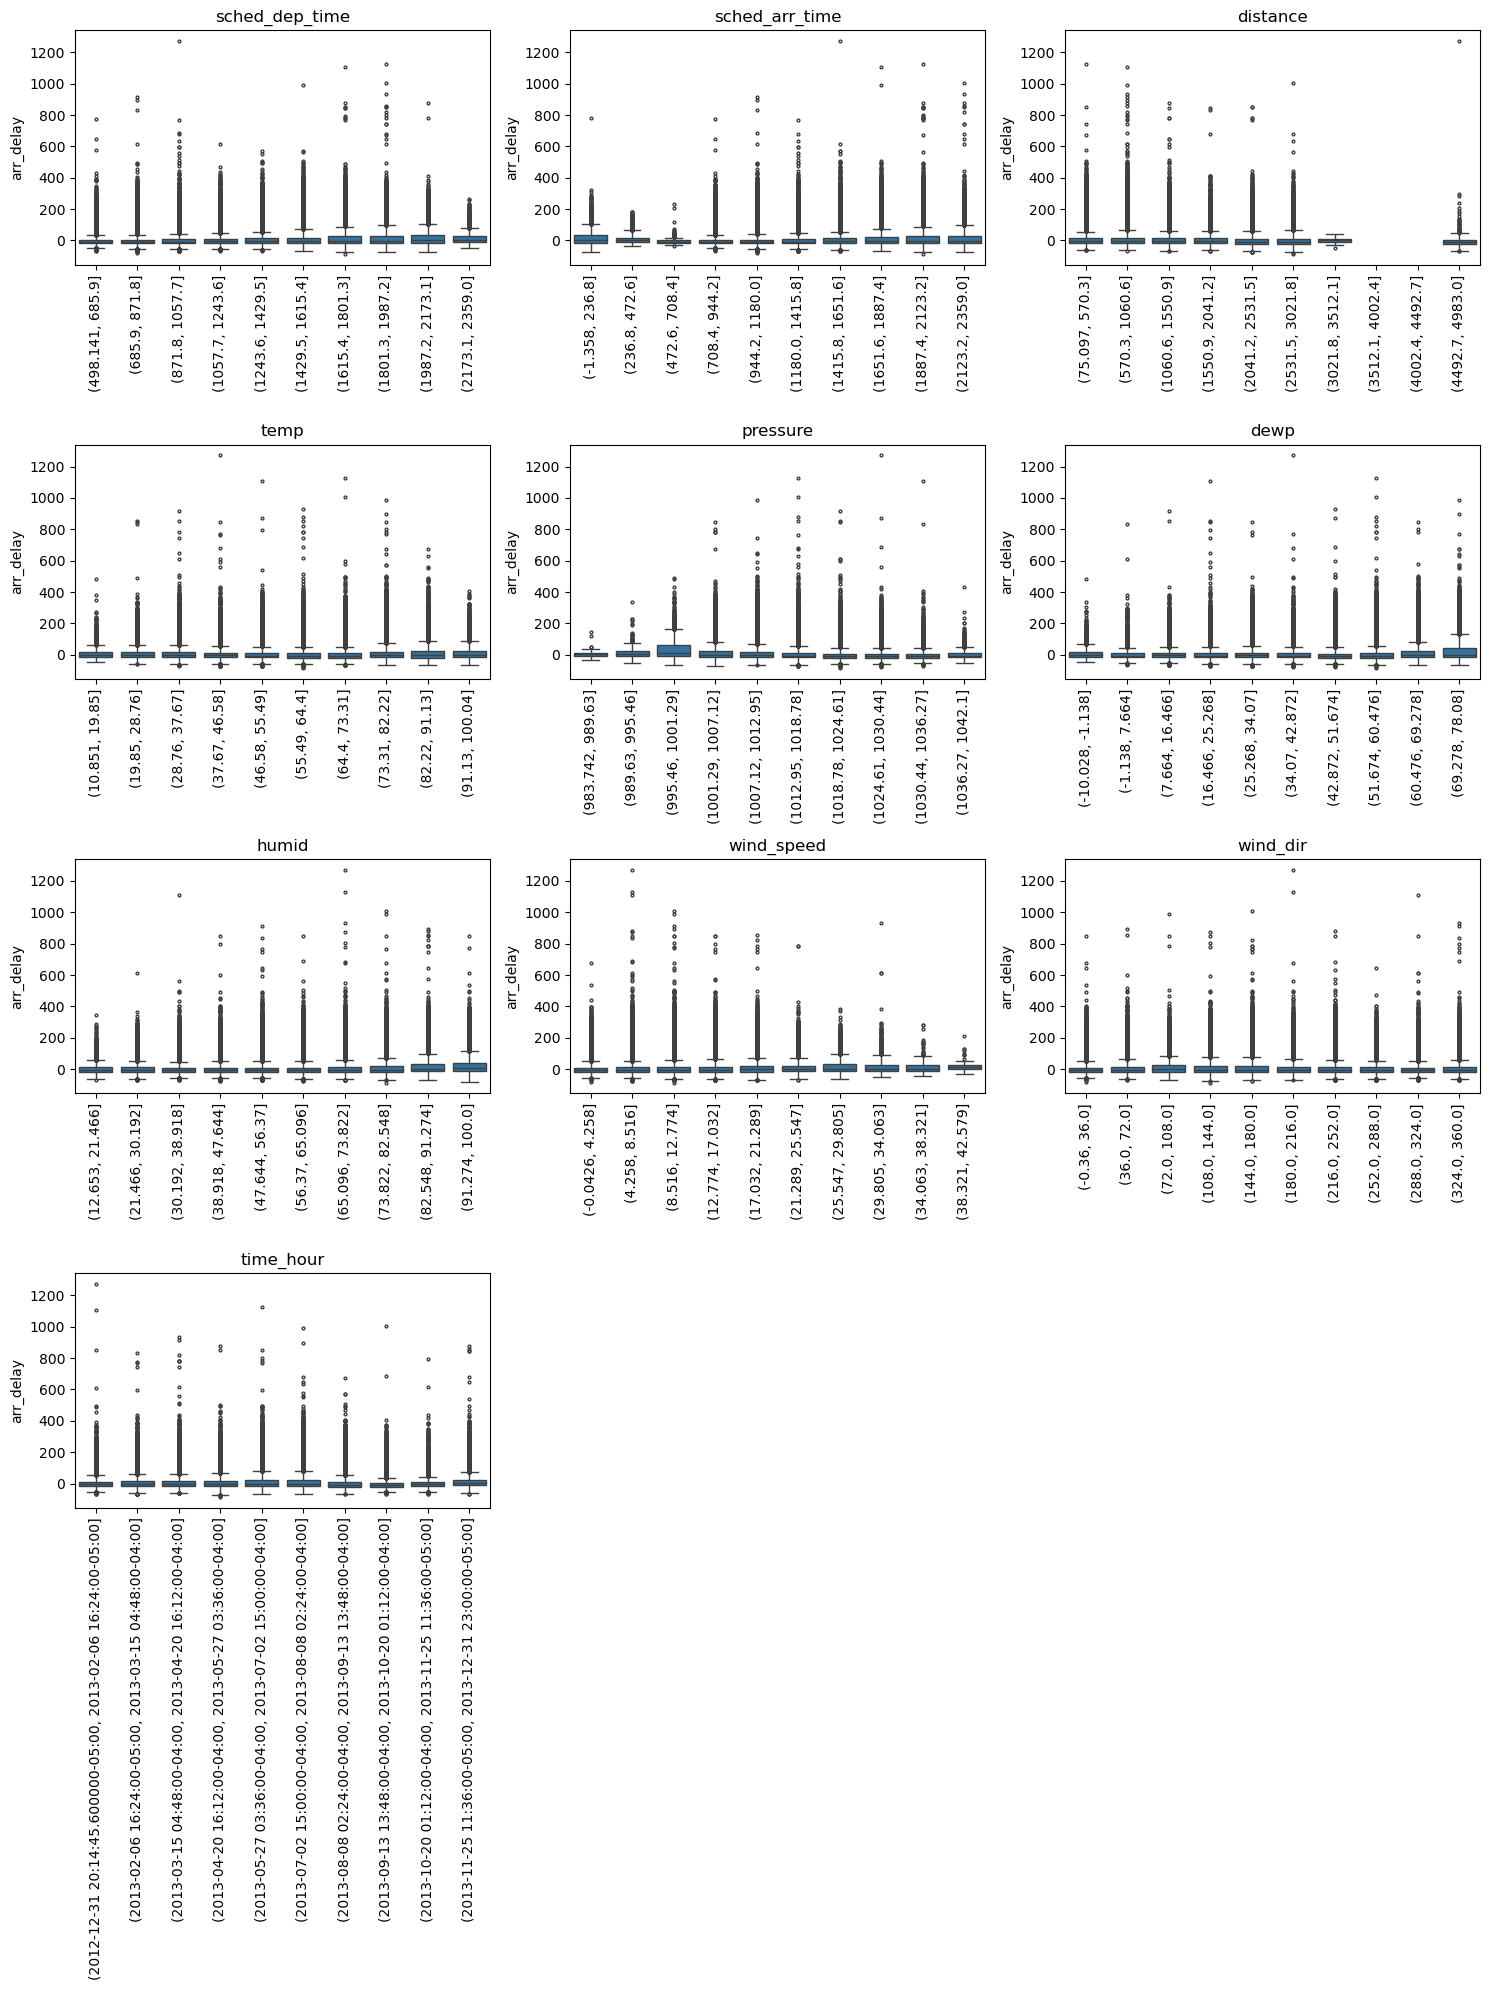

In [33]:
# Boxplots of some of the continuous variables to review outliers and general distributions

# Manually create a set of numerical columns - cont
continuous_numerical_cols = [
    'sched_dep_time',
    'sched_arr_time',
    'distance',
    'temp',
    'pressure',
    'dewp',
    'humid',
    'wind_speed',
    'wind_dir',
    'time_hour'
]

def plot_binned_boxplot(ax, x, y, bins=10):
    valid = x.notna() & y.notna()
    x = x[valid]
    y = y[valid]

    binned = pd.cut(x, bins=bins, duplicates="drop")

    plot_df = pd.DataFrame({
        "bin": binned,
        "arr_delay": y
    })

    sns.boxplot(
        data=plot_df,
        x="bin",
        y="arr_delay",
        ax=ax,
        fliersize=2,
        showfliers=True,
        linewidth=1
    )

    ax.set_xlabel("")
    ax.set_ylabel("arr_delay")
    ax.tick_params(axis="x", rotation=90)

n_cols = 3
n_rows = math.ceil(len(continuous_numerical_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 5*n_rows))
axes = axes.flatten()

for ax, col in zip(axes, continuous_numerical_cols):
    plot_binned_boxplot(ax, df[col], df['arr_delay'], bins=10)
    ax.set_title(col)

# Remove unused axes
for ax in axes[len(continuous_numerical_cols):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


<h3>As is visible above, each of the continuous numerical features is dominated by outliers. This makes it very difficult to predict 'arr_delay' as a target variable. It is this, and the fact that the task asks to predict whether the flight was late or Not (binary) that we choose to, next, introduce a 'latency' column. </h3>

<br>

<h3>Note that at this point, we have observed no absurd data in df after the split. It turns out there is weather data that is unrealistic, and therefore erranous, but it is not present in df. This is also evident through the plots produced above and below.</h3>

<h2>4.3 Introducing 'latency' column

In [34]:
# latency threshold
lat_threshold = 15

# Introduce a 'latency' column, which is a binary variable indicating whether the flight was delayed by more than 0 minutes.
df['latency'] = (df['arr_delay'] > lat_threshold).astype(int)

# Primnt the number of flights more than 0 mins ar_delay and the number than at <= 0 arr_delay
num_delayed = (df['arr_delay'] > lat_threshold).sum()
num_Not_delayed = (df['arr_delay'] <= lat_threshold).sum()
print(f'Number of flights with arr_delay > {lat_threshold}: {num_delayed}')
print(f'Number of flights with arr_delay <= {lat_threshold}: {num_Not_delayed}')

Number of flights with arr_delay > 15: 77630
Number of flights with arr_delay <= 15: 249716


<h2>4.4 Splitting Dataset into train/val and test</h2>


In [58]:
def random_time_blocks_split(df, time_col, val_frac=0.20, n_blocks=8, random_state=5059):
    """
    Returns df_train, df_val where df_val consists of n_blocks
    contiguous chronological blocks totalling val_frac of data.
    """

    # sort by time but keep original index
    df_sorted = df.sort_values(time_col).reset_index()
    original_index = df_sorted["index"].to_numpy()
    n = len(df_sorted)

    block_len = int(round((val_frac / n_blocks) * n))
    block_len = max(1, block_len)

    rng = np.random.default_rng(random_state)

    max_start = n - block_len
    occupied = np.zeros(n, dtype=bool)
    starts = []

    attempts = 0
    while len(starts) < n_blocks:
        attempts += 1
        if attempts > 10000:
            raise RuntimeError("Couldn't sample non-overlapping blocks.")

        s = int(rng.integers(0, max_start + 1))
        e = s + block_len

        if occupied[s:e].any():
            continue

        occupied[s:e] = True
        starts.append(s)

    # mark validation rows
    val_mask_sorted = np.zeros(n, dtype=bool)
    for s in starts:
        val_mask_sorted[s:s+block_len] = True

    val_idx = original_index[val_mask_sorted]
    train_idx = original_index[~val_mask_sorted]

    df_train = df.loc[train_idx].copy()
    df_val   = df.loc[val_idx].copy()

    return df_train, df_val, starts, block_len


In [61]:
# example: split off last 15% as test first
df_sorted = df.sort_values("time_hour")
test_cut = int(len(df_sorted) * 0.15)

df_test = df_sorted.iloc[-test_cut:]
df_trainval = df_sorted.iloc[:-test_cut]


df_train, df_val, starts, block_len = random_time_blocks_split(df_trainval, time_col="time_hour", val_frac=0.175, n_blocks=8, random_state=5059)


print(len(df_train), len(df_val))



229549 48696


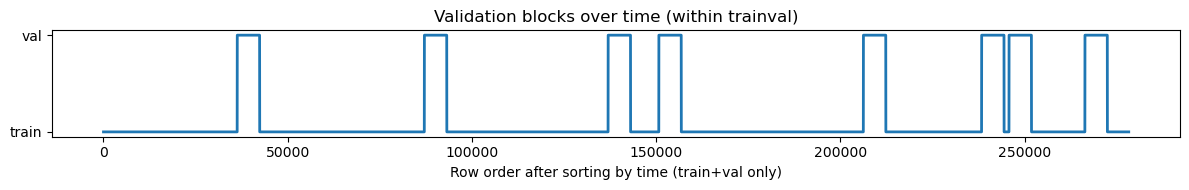

In [62]:
def plot_split_blocks_trainval(df_trainval, df_val, time_col="time_hour", title="Validation blocks within train/val set"):

    # sort train+val chronologically
    df_sorted = df_trainval.sort_values(time_col)

    # mark validation rows
    is_val = df_sorted.index.isin(df_val.index).astype(int)

    plt.figure(figsize=(12, 2))
    plt.plot(is_val, linewidth=2)

    plt.yticks([0, 1], ["train", "val"])
    plt.xlabel("Row order after sorting by time (train+val only)")
    plt.title(title)

    plt.tight_layout()
    plt.show()

plot_split_blocks_trainval(df_trainval, df_val, time_col="time_hour", title="Validation blocks over time (within trainval)")

<h2>4.5 Feature Engineering</h2>

In [38]:
%pip install holidays

  Using cached holidays-0.91-py3-none-any.whl.metadata (50 kB)
  Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl.metadata (8.4 kB)
Using cached holidays-0.91-py3-none-any.whl (1.4 MB)
Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl (229 kB)
  Attempting uninstall: python-dateutil
    Found existing installation: python-dateutil 2.9.0
    Uninstalling python-dateutil-2.9.0:
      Successfully uninstalled python-dateutil-2.9.0

[notice] A new release of pip is available: 24.1.2 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import holidays

def add_engineered_features(
    df_in: pd.DataFrame,
    *,
    year=2013,
    peak_hours=(6, 7, 8, 9, 16, 17, 18, 19),
    window="10h",
    buffer_minutes=60,
) -> pd.DataFrame:
    """
    Adds engineered features:
      - is_peak (rush hour based on df['hour'])
      - is_holiday (US holiday based on df['time_hour'])
      - actual_arrival_time (approx: time_hour + arr_delay minutes)
      - delay_rate_prev10h (rolling mean of latency in previous 'window'
        based on actual_arrival_time, shifted by 1 to avoid peeking)

    Requirements: columns ['hour','time_hour','origin','arr_delay','latency'].
    Returns a NEW dataframe with added columns.
    """
    df = df_in.copy()

    # is_peak
    df["is_peak"] = df["hour"].isin(list(peak_hours)).astype(int)

    # is_holiday
    us_holidays = holidays.US(years=[year])
    df["time_hour"] = pd.to_datetime(df["time_hour"])
    df["is_holiday"] = df["time_hour"].dt.date.isin(us_holidays).astype(int)

    # Rolling delay feature
    BUFFER = pd.Timedelta(minutes=buffer_minutes)

    # approximate actual arrival time
    df["actual_arrival_time"] = df["time_hour"] + pd.to_timedelta(df["arr_delay"], unit="m")

    # ensure deterministic order
    df = df.sort_values(["origin", "actual_arrival_time"])

    results = []
    for origin, g in df.groupby("origin", sort=False):
        g = g.sort_values("actual_arrival_time").copy()

        rolled = (
            g.set_index("actual_arrival_time")["latency"]
             .rolling(window)
             .mean()
        )

        g["delay_rate_prev10h"] = rolled.values

        # enforce "only earlier arrivals" (and buffer) via shift-by-1
        g["delay_rate_prev10h"] = g["delay_rate_prev10h"].shift(1).fillna(0)

        results.append(g)

    df_out = pd.concat(results).sort_index()
    return df_out

df_train = add_engineered_features(df_train)
df_val   = add_engineered_features(df_val)







[autoreload of dateutil.tz._factories failed: Traceback (most recent call last):
  File "/opt/conda/lib/python3.11/site-packages/IPython/extensions/autoreload.py", line 276, in check
    superreload(m, reload, self.old_objects)
  File "/opt/conda/lib/python3.11/site-packages/IPython/extensions/autoreload.py", line 500, in superreload
    update_generic(old_obj, new_obj)
  File "/opt/conda/lib/python3.11/site-packages/IPython/extensions/autoreload.py", line 397, in update_generic
    update(a, b)
  File "/opt/conda/lib/python3.11/site-packages/IPython/extensions/autoreload.py", line 365, in update_class
    update_instances(old, new)
  File "/opt/conda/lib/python3.11/site-packages/IPython/extensions/autoreload.py", line 323, in update_instances
    object.__setattr__(ref, "__class__", new)
TypeError: can't apply this __setattr__ to _TzSingleton object
]
[autoreload of dateutil.rrule failed: Traceback (most recent call last):
  File "/opt/conda/lib/python3.11/site-packages/IPython/extens

<h2>5.0 Graphing attributes</h2>

<br>

<h3>We graph from the full dataframe df for a full picture of the data. The models will use the pre-divided train and validate dataframes.</h3>

In [40]:
target = 'latency'

# Continuous set already created above

# Manually create a set of numerical columns - discrete

discrete_numerical_cols = [
    'month',
    'day',
    'hour',
    'minute',
    'engines_plane',
    'precip',
    'visib',
    'age_plane'
]

# Manually create a set of categorical columns

categorical_cols = [
    'carrier',
    'origin',
    'dest',
    'type_plane',
    'manufacturer_plane',
    'model_plane',
    'engine_plane',
]


In [41]:
# Funciton to plot the probability of being late for each category in a categorical variable
def plot_categorical_prob(ax, df, col, target, min_frac=0.05):
    sub = df[[col, target]].dropna()

    grouped = sub.groupby(col, observed=True)[target]

    probs = grouped.mean()
    counts = grouped.size()

    # order by increasing probability of being late
    probs = probs.sort_values(ascending=True)
    counts = counts.loc[probs.index]

    # bin relative threshold. Any bin with less than min_frac * 100 % of the expected number of data points is coloured red.
    # This helps visualise where the bulk of the data is and is not.
    expected = len(sub) / len(probs)
    threshold = min_frac * expected

    colors = [
        "red" if counts[c] < threshold else "steelblue"
        for c in probs.index
    ]

    ax.bar(probs.index.astype(str), probs.values, color=colors)
    ax.set_ylabel("P(late)")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=90)


# Function to plot the probability of being late for each category in a discrete numerical variable
def plot_discrete_prob(ax, df, col, target, min_frac=0.05):
    sub = df[[col, target]].dropna()

    grouped = sub.groupby(col, observed=True)[target]

    probs = grouped.mean().sort_index()
    counts = grouped.size().loc[probs.index]

    expected = len(sub) / len(probs)
    threshold = min_frac * expected

    colors = ["red" if counts[c] < threshold else "steelblue"
              for c in probs.index]

    ax.bar(probs.index.astype(str), probs.values, color=colors)
    ax.set_ylabel("P(late)")
    ax.set_title(col)
    ax.set_xlabel(col)



# Function to plot the probability of being late for each category in a continuous numerical variable, by binning the variable into 10 equal-width bins
def plot_continuous_binned_prob(ax, df, col, target, bins=15, min_frac=0.10):
    sub = df[[col, target]].dropna()

    binned = pd.cut(sub[col], bins=bins, duplicates="drop")
    grouped = sub.groupby(binned, observed=False)[target]

    probs = grouped.mean()
    counts = grouped.size()

    expected = len(sub) / len(probs)
    threshold = min_frac * expected

    colors = ["red" if c < threshold else "steelblue" for c in counts]

    labels = [f"{b.left:.2g}–{b.right:.2g}" for b in probs.index]

    ax.bar(range(len(probs)), probs.values, color=colors)
    ax.set_xticks(range(len(probs)))
    ax.set_xticklabels(labels, rotation=45, fontsize=8)
    ax.set_ylabel("P(late)")
    ax.set_title(col)


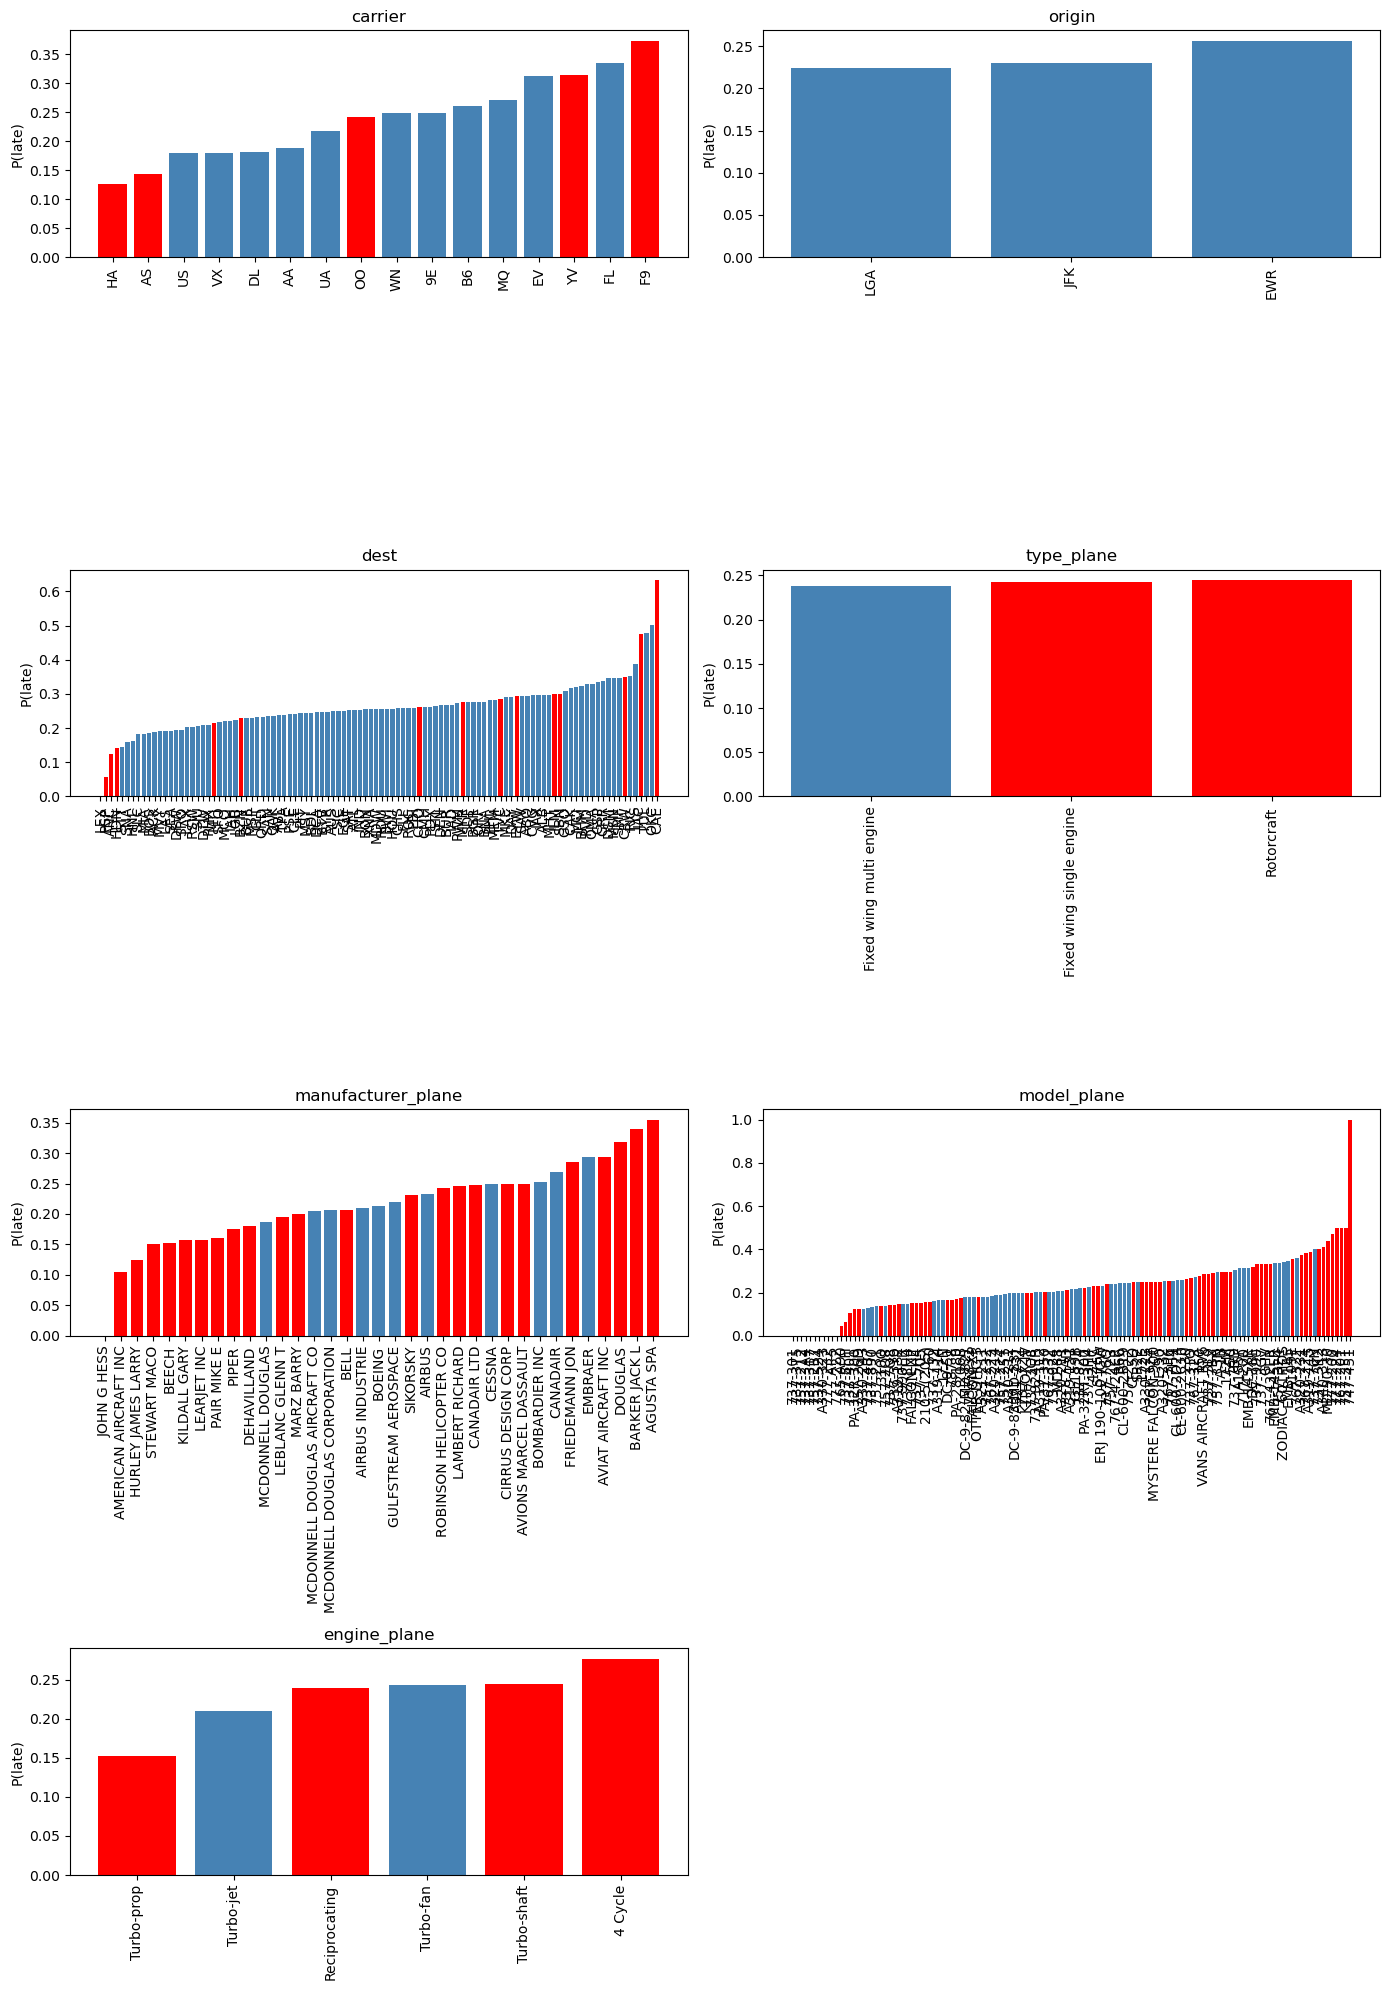

In [42]:
# Plot the probability of being late for each category in each categorical variable
n_cols = 2
n_rows = math.ceil(len(categorical_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(7*n_cols, 5*n_rows))
axes = axes.flatten()

for ax, col in zip(axes, categorical_cols):
    plot_categorical_prob(ax, df, col, target)

for ax in axes[len(categorical_cols):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

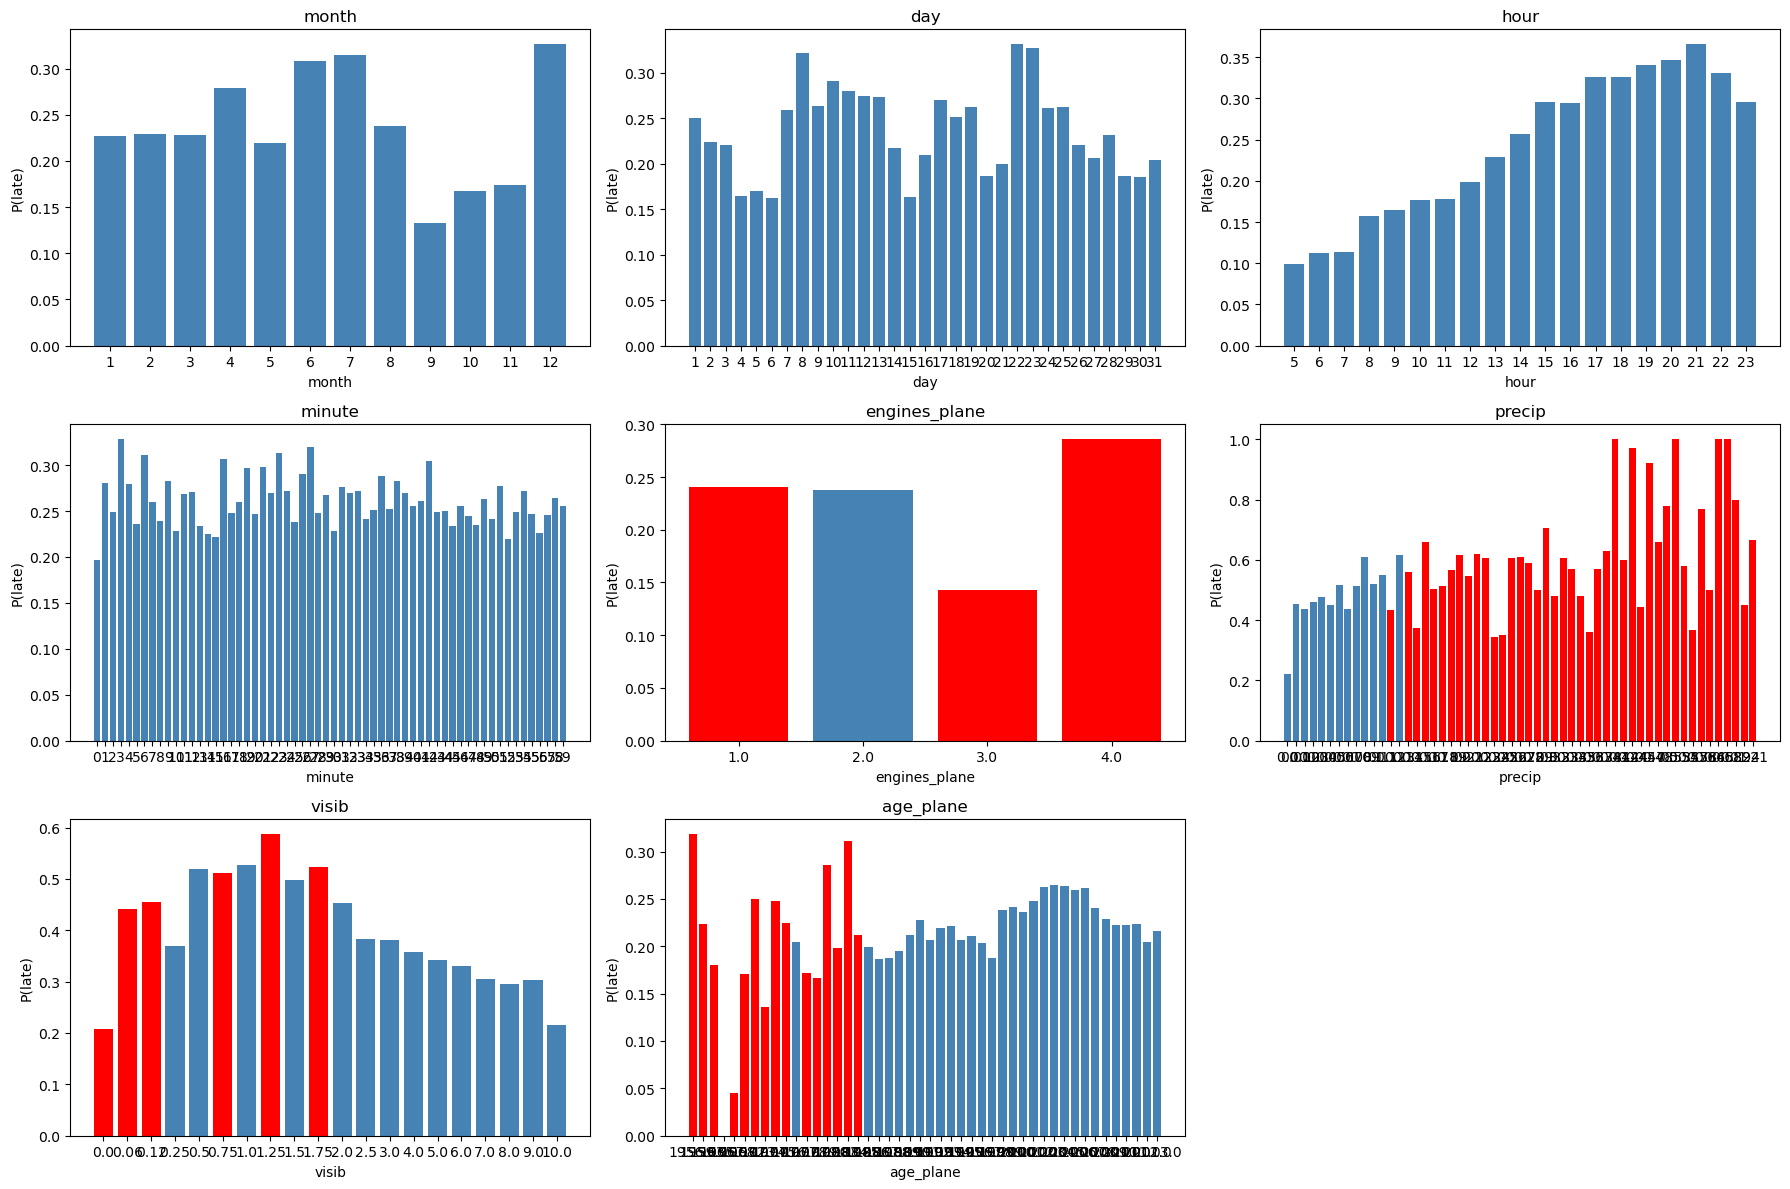

In [43]:
# Plot the probability of being late for each category in each discrete numerical variable
n_cols = 3
n_rows = math.ceil(len(discrete_numerical_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 4*n_rows))
axes = axes.flatten()

for ax, col in zip(axes, discrete_numerical_cols):
    plot_discrete_prob(ax, df, col, target)

for ax in axes[len(discrete_numerical_cols):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

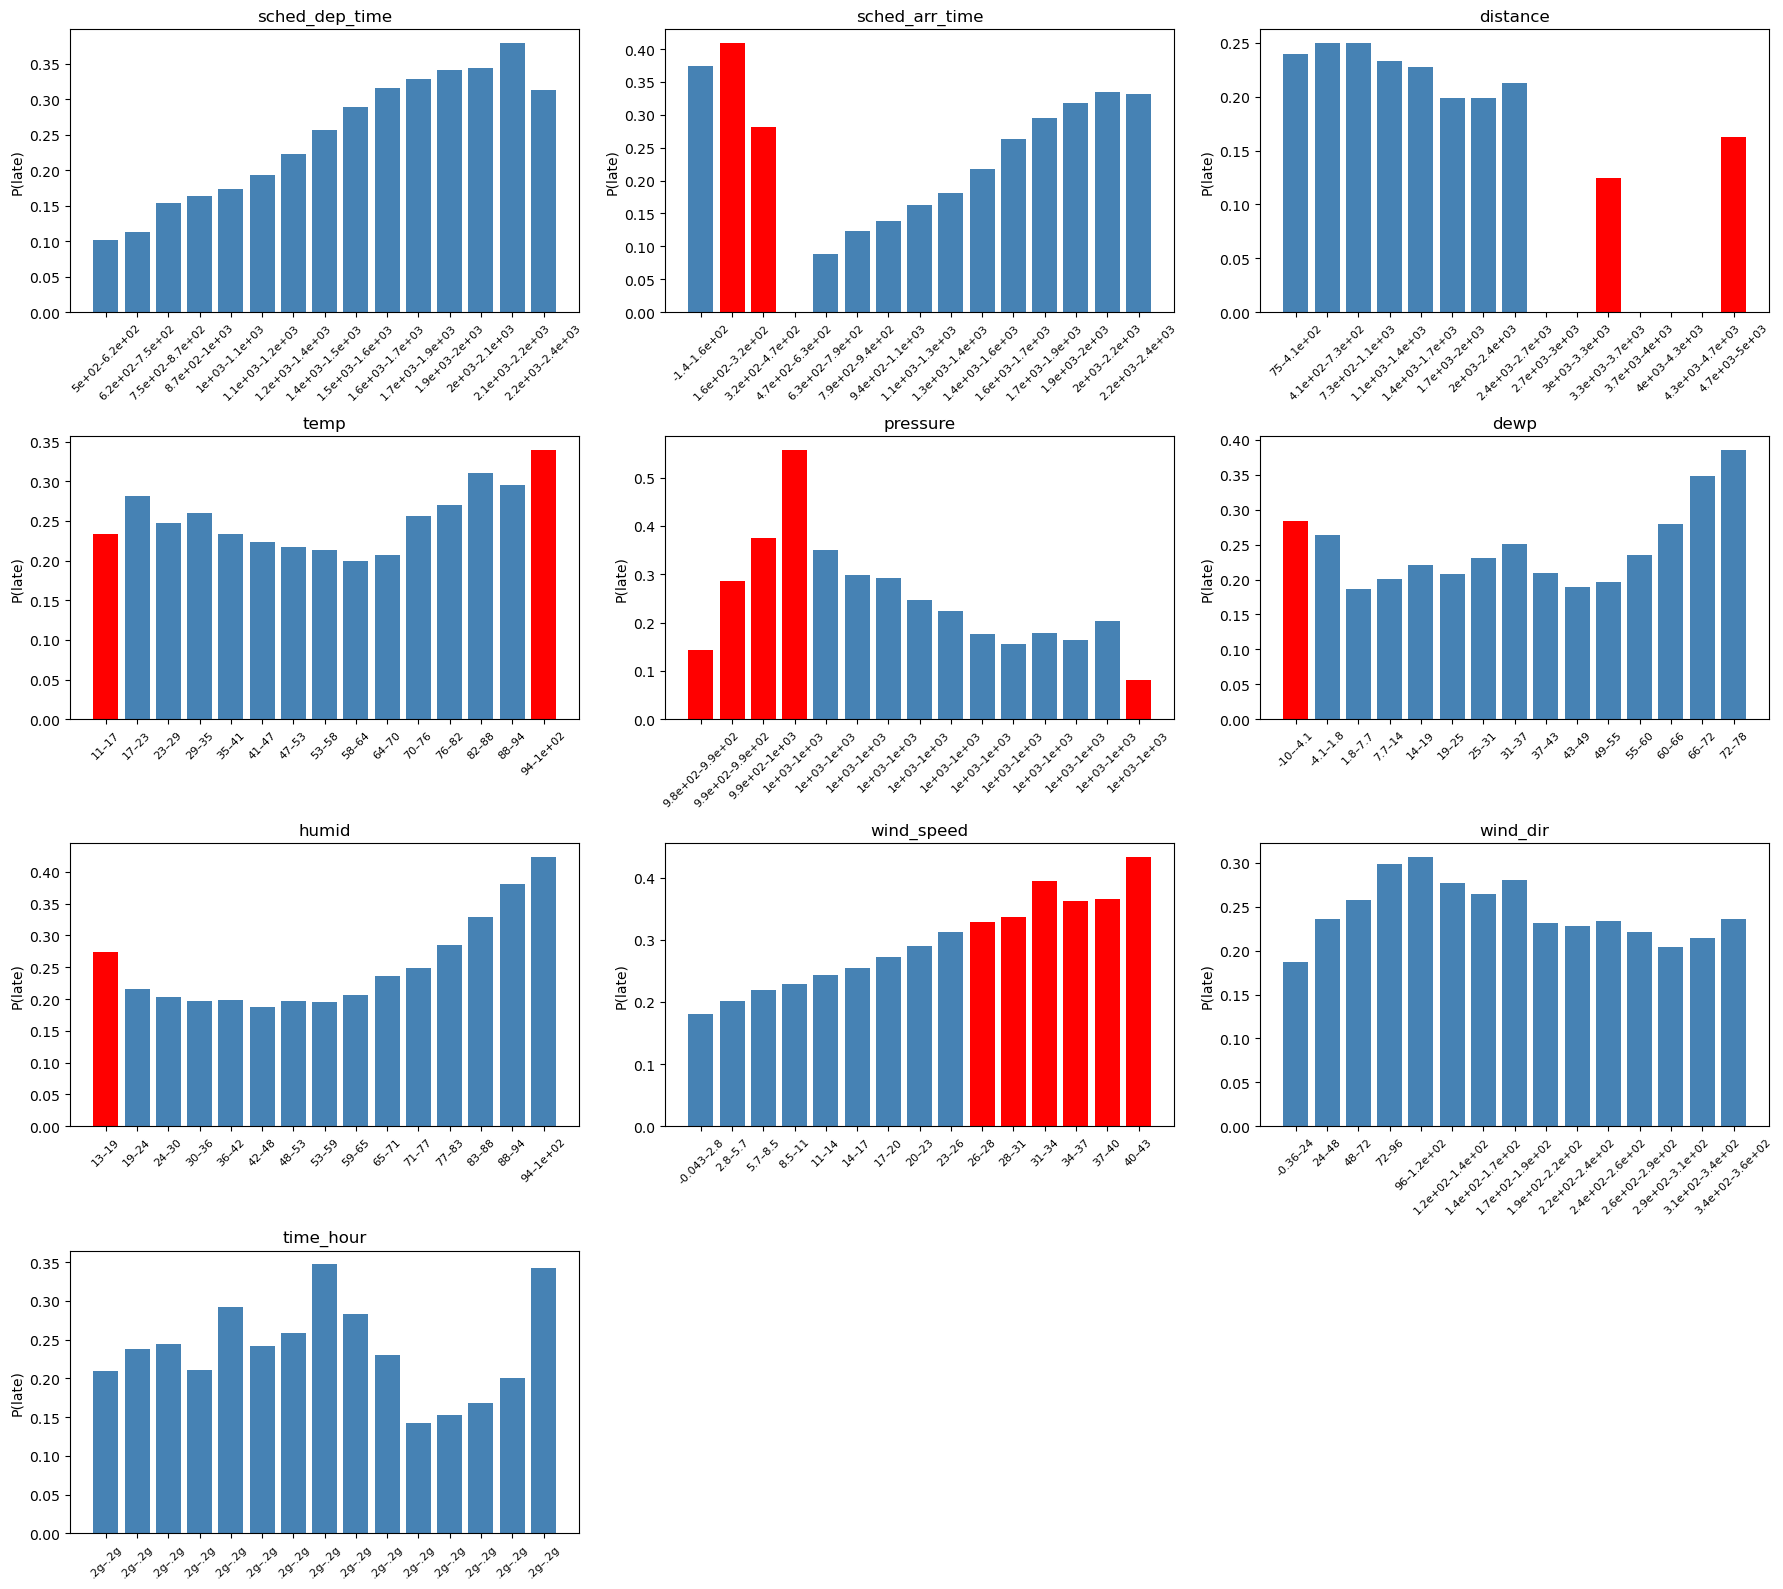

In [44]:
# Plot the probability of being late for each category in each continuous numerical variable
n_cols = 3
n_rows = math.ceil(len(continuous_numerical_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 4*n_rows))
axes = axes.flatten()

for ax, col in zip(axes, continuous_numerical_cols):
    plot_continuous_binned_prob(ax, df, col, target, bins=15) # We choose 15 bins because 10 is artificially smooth, where as 20 is too choppy (Noisy).

for ax in axes[len(continuous_numerical_cols):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

<h3>Please note in the above plots, the red columns are those (or bins) that contain less than a certain proportion (see above) of the expected number of data points. This allows some (non-rigorous) consideration of how spread the data is and how reliable the plots are for inference.

<h2>5.1 Correlation plots

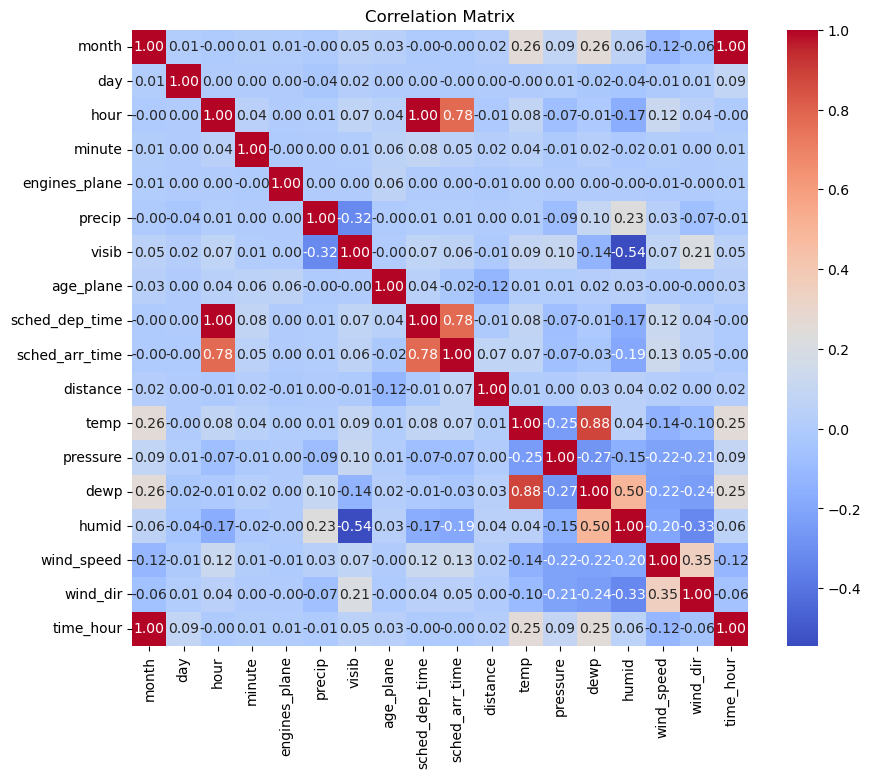

In [45]:
# Print a small corr plot for the discrete and continuous numerical variables

# Select only the discrete and continuous numerical variables
num_cols = discrete_numerical_cols + continuous_numerical_cols
corr = df[num_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Matrix")
plt.show()

<h2>5.2 Plotting the engineered features (training data)</h2>

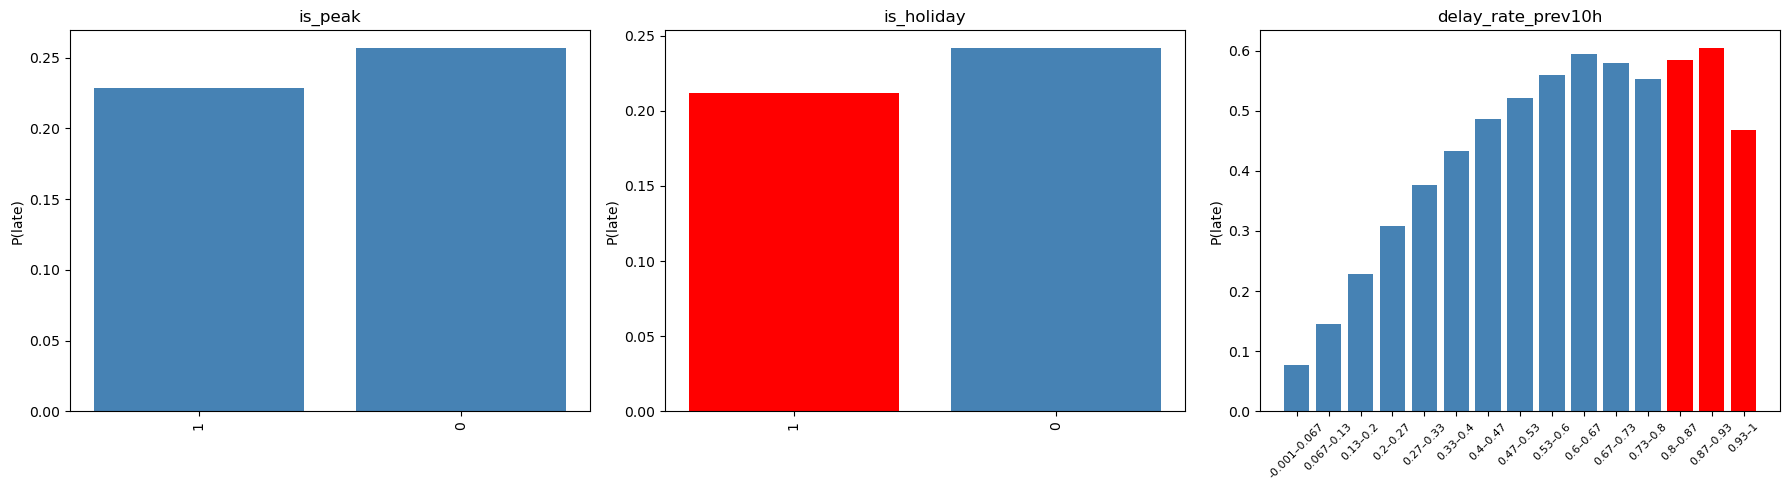

In [46]:
# Plot the engineered features

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# is_peak (categorical/binary)
plot_categorical_prob(axes[0], df_train, "is_peak", target)

# is_holiday (categorical/binary)
plot_categorical_prob(axes[1], df_train, "is_holiday", target)

# delay_rate_prev10h (continuous)
plot_continuous_binned_prob(axes[2], df_train, "delay_rate_prev10h", target, bins=15)

plt.tight_layout()
plt.show()

<h2>5.2 Analysis

| Categorical feature | Graphic differences in latency | Keep | Comments |
| --- | --- | --- | --- |
| carrier | clear differences | Yes | The data is well spread across the different carriers and there are disparities in prob of latency | 
| dest | clear differences | Yes | Clear differences in latency across destinations and data is well spread |
| type_plane | no clear differences | No | No significant differences between types |
| manufacturer_plane | clear differences | Yes | Similar to model; will use for time being |
| model_plane | clear differences | Yes | Clear differences in latency and data is reasonably well spread (blue lines across board) |
| engine_plane | no clear differences | No | Data is not well spread across categories. Any difference should be covered by model |
| is_holiday | no clear difference | No | There are not enough holidays to make the data useful to a model |
| is_peak | no clear difference | No | Not a sufficiently large difference. Not useful to a model |

<br>

| Discrete numerical feature | Graphic trend with latency | Correlation | Keep | Comments |
| --- | --- | --- | --- | --- |
| Month | Clear trend | | Yes | Peaks during the summer and winter seasons, as expected |
| day | No clear trend | | No | |
| hour | clear trend | sched_dep_time and sched_arr_time | Yes | Later flights appear to be delayed more often. Data well spread |
| min | No clear trend | | No | |
| engines_plane | No significant impact | | No | The only outlier is 3-engined planes, data spread poorly |
| precip | clear trend | (-)visib | Yes | Despite huge data bias towards low precip values, we see a steep increase in delays as rain increases |
| visib | potentially trend | (-)humid and (-)precip | No | Unexpectedly quadratic due to biased data spread (see 4.1 above). Will still use. |
| age_plane | No clear trend | | No | |

<br>

| Continuous numerical feature | Graphic trend with latency | Correlation | Keep | Comments |
|-----------------------------|---------------|-------------|------|---|
| sched_dep_time | clear trend | hour, sched_arr_time | No | The same as hour |
| sched_arr_time | clear trend | sched_dep_time, hour | No | Highly correlated with hour |
| distance | No clear trend | | No |
| temp | Small trend | dewp, (-)pressure | Yes | Slightly quadratic as expected |
| pressure | clear trend | (-)temp | Yes | Lower pressure appears to be associated with more delays |
| dewp | Significant deviance | humid, temp | Yes | Might make a difference in a model. Definitely not linear |
| humid | clear trend | dewp, (-)visib | Yes | Clear trend and good data spread. Correlates with humidity |
| wind_speed | clear trend | wind_dir | Yes | Greater wind speed increases probability of delay |
| wind_dir | slight mode | wind_speed | Yes | Potentially a slight mode |
| time_hour | No clear trend | month | No | |
| delay_rate_prev10h | Clear relationship | Not really | Yes | As expected, strong relationship. Slightly unexpected values on the far right side (red columns indicate weak data)|


<h3>Comments: a number of the above features that have been selected do exhibit correlation or issues. Satisfied that these issues are not hugely significant, we choose to progress them anyway. In the last stage, we wil reduce to the most impactful features to keep the model simple.</h3>

<h2>6.0 Model design

<h3>Logistic Regression

In [47]:
# Logistic Regression with 5-Fold Cross-Validation

# Preprocessing and pipeline
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Models
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import SGDClassifier  # For SVM

# Model evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix


# Define feature columns

num_mod1_cols = ["precip","temp","pressure","dewp","humid","wind_speed","wind_dir","delay_rate_prev10h"]
categorical_mod1_cols = ['hour', 'month', 'model_plane', 'dest', 'carrier', 'manufacturer_plane']

mod1_cols = num_mod1_cols + categorical_mod1_cols


# Define X and y

X_train_raw = df_train[mod1_cols]
y_train = df_train['latency']

X_val_raw = df_val[mod1_cols]
y_val = df_val['latency']




  Using cached xgboost-3.2.0-py3-none-manylinux_2_28_x86_64.whl.metadata (2.1 kB)
  Using cached nvidia_nccl_cu12-2.29.3-py3-none-manylinux_2_18_x86_64.whl.metadata (2.1 kB)
Using cached xgboost-3.2.0-py3-none-manylinux_2_28_x86_64.whl (131.7 MB)
Using cached nvidia_nccl_cu12-2.29.3-py3-none-manylinux_2_18_x86_64.whl (289.8 MB)

[notice] A new release of pip is available: 24.1.2 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

==================== Logistic Regression ====================
Train classification report:
              precision    recall  f1-score   support

           0     0.8753    0.7431    0.8038    173943
           1     0.4516    0.6665    0.5384     55199

    accuracy                         0.7247    229142
   macro avg     0.6635    0.7048    0.6711    229142
weighted avg     0.7733    0.7247    0.7399    229142

Validation classification report:
              precision    recall  f1-

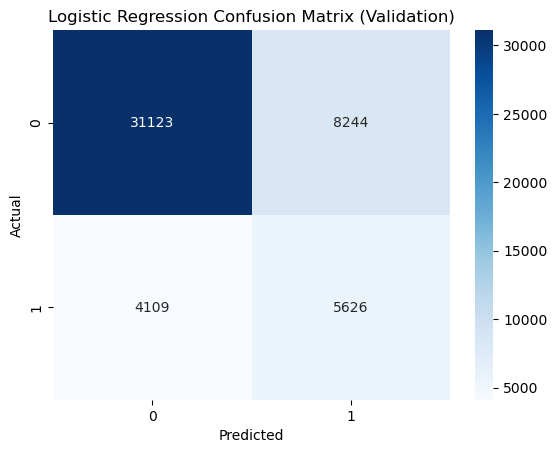


==================== Random Forest ====================
Train classification report:
              precision    recall  f1-score   support

           0     0.9113    0.8606    0.8852    173943
           1     0.6262    0.7360    0.6767     55199

    accuracy                         0.8306    229142
   macro avg     0.7688    0.7983    0.7809    229142
weighted avg     0.8426    0.8306    0.8350    229142

Validation classification report:
              precision    recall  f1-score   support

           0     0.8771    0.8815    0.8793     39367
           1     0.5108    0.5005    0.5056      9735

    accuracy                         0.8059     49102
   macro avg     0.6939    0.6910    0.6924     49102
weighted avg     0.8045    0.8059    0.8052     49102

Train ROC-AUC: 0.9053 | Train AP (PR-AUC): 0.7716
Val   ROC-AUC: 0.7749 | Val   AP (PR-AUC): 0.5380


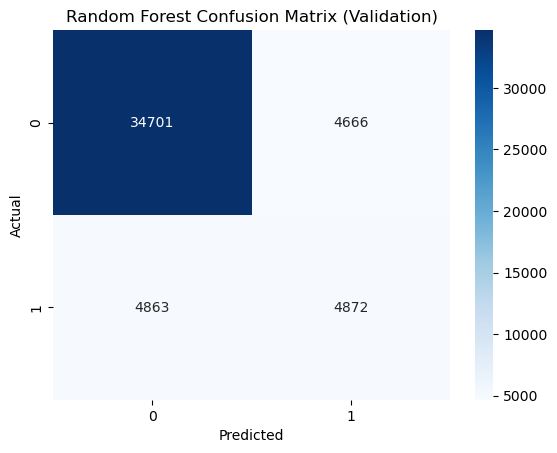


==================== XGBoost ====================
Train classification report:
              precision    recall  f1-score   support

           0     0.9002    0.8096    0.8525    173943
           1     0.5444    0.7172    0.6190     55199

    accuracy                         0.7873    229142
   macro avg     0.7223    0.7634    0.7357    229142
weighted avg     0.8145    0.7873    0.7962    229142

Validation classification report:
              precision    recall  f1-score   support

           0     0.8843    0.8429    0.8631     39367
           1     0.4658    0.5542    0.5062      9735

    accuracy                         0.7856     49102
   macro avg     0.6751    0.6985    0.6846     49102
weighted avg     0.8014    0.7856    0.7923     49102

Train ROC-AUC: 0.8508 | Train AP (PR-AUC): 0.6983
Val   ROC-AUC: 0.7797 | Val   AP (PR-AUC): 0.5643


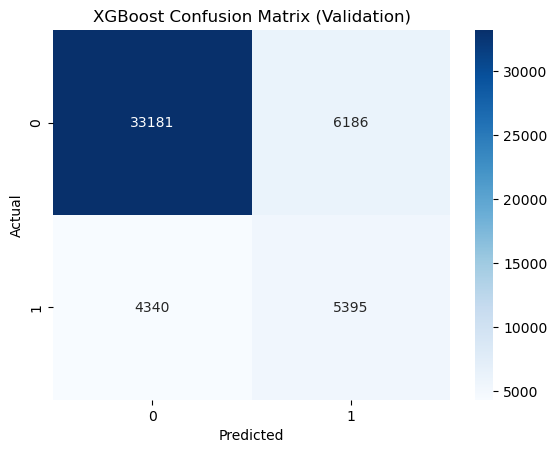

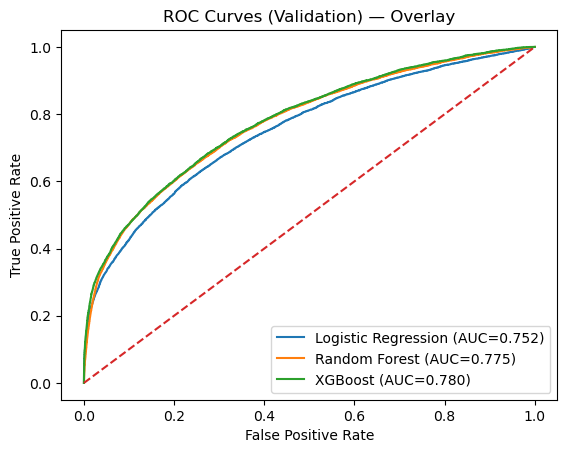

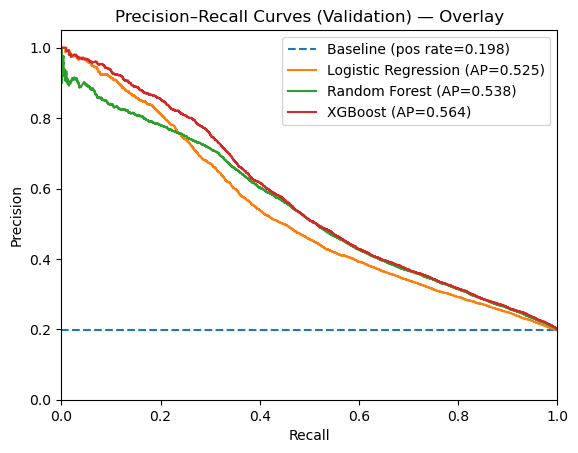

In [48]:
# -----------------------------
# Imports
# -----------------------------
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score
)

# In case XGBoost is not installed (it wasn't on the school jupyter notebook)
%pip install xgboost

from xgboost import XGBClassifier


# Define numeric and categorical pipelines
numeric_pipeline = Pipeline([
    ('num_imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('cat_imputer', SimpleImputer(strategy='most_frequent')),
    ('one_hot', OneHotEncoder(handle_unknown='ignore'))
])

# Full preprocessing pipeline
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, num_mod1_cols),
    ('cat', categorical_pipeline, categorical_mod1_cols)
])

# # Split FIRST
# X_train_raw, X_val_raw, y_train, y_val = train_test_split(
#     X,
#     y,
#     test_size=0.2,
#     random_state=5059,
#     stratify=y
# )

# Fit preprocessor ONLY on training data
X_train = preprocessor.fit_transform(X_train_raw)

# Transform validation data
X_val = preprocessor.transform(X_val_raw)

# Define models
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=5,
    random_state=5059,
    class_weight='balanced',
    n_jobs=-1
)

log_model = LogisticRegression(
    solver='newton-cholesky',
    penalty='l2',
    C=1.0,
    max_iter=2000,
    class_weight='balanced'
)

# XGBoost class imbalance handling scale_pos_weight = neg/pos
pos = np.sum(y_train == 1)
neg = np.sum(y_train == 0)
scale_pos_weight = (neg / pos) if pos > 0 else 1.0

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    min_child_weight=1,
    gamma=0.0,
    random_state=5059,
    n_jobs=-1,
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight
)

models = [
    ("Logistic Regression", log_model),
    ("Random Forest", rf_model),
    ("XGBoost", xgb_model),
]

# Fit models
for name, model in models:
    if name == "XGBoost":
        model.fit(
            X_train, y_train,
            eval_set=[(X_val, y_val)],
            verbose=False
        )
    else:
        model.fit(X_train, y_train)

# Evaluate classification_report + confusion matrix + store ROC/PR data
roc_data = {}  # name (fpr, tpr, auc)
pr_data = {}   # name (recall, precision, ap)

def evaluate_model(model, X_tr, y_tr, X_vl, y_vl, name):
    # Predictions
    y_pred_tr = model.predict(X_tr)
    y_pred_vl = model.predict(X_vl)

    # Probabilities (for ROC/PR)
    y_prob_tr = model.predict_proba(X_tr)[:, 1]
    y_prob_vl = model.predict_proba(X_vl)[:, 1]

    # ---- Primary diagnostic: classification report ----
    print(f"\n==================== {name} ====================")
    print("Train classification report:")
    print(classification_report(y_tr, y_pred_tr, digits=4))
    print("Validation classification report:")
    print(classification_report(y_vl, y_pred_vl, digits=4))

    # Other summary stats
    train_auc = roc_auc_score(y_tr, y_prob_tr)
    val_auc = roc_auc_score(y_vl, y_prob_vl)
    train_ap = average_precision_score(y_tr, y_prob_tr)
    val_ap = average_precision_score(y_vl, y_prob_vl)

    print(f"Train ROC-AUC: {train_auc:.4f} | Train AP (PR-AUC): {train_ap:.4f}")
    print(f"Val   ROC-AUC: {val_auc:.4f} | Val   AP (PR-AUC): {val_ap:.4f}")

    # Confusion matrix (validation)
    cm = confusion_matrix(y_vl, y_pred_vl)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'{name} Confusion Matrix (Validation)')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    # Store ROC curve data (validation)
    fpr, tpr, _ = roc_curve(y_vl, y_prob_vl)
    roc_data[name] = (fpr, tpr, val_auc)

    # Store Precision-Recall curve data (validation)
    precision, recall, _ = precision_recall_curve(y_vl, y_prob_vl)
    pr_data[name] = (recall, precision, val_ap)

# Run evaluation
for name, model in models:
    evaluate_model(model, X_train, y_train, X_val, y_val, name)

# Overlay ROC curves (validation)
plt.figure()
for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves (Validation) — Overlay")
plt.legend()
plt.show()

# Overlay Precision–Recall curves (validation)
plt.figure()
baseline = y_val.mean()
plt.plot([0, 1], [baseline, baseline], linestyle='--',
         label=f"Baseline (pos rate={baseline:.3f})")

for name, (recall, precision, ap) in pr_data.items():
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves (Validation) — Overlay")
plt.ylim(0, 1.05)
plt.xlim(0, 1.0)
plt.legend()
plt.show()


<h2>7.0 Selecting and refining a model</h2>

<h3>As per the above results, I am most impressed by the results from the XGBoost model. Accordingly, I will now seek to optimise this model's performence and also ascertain which features should be retained in a more compact model.</h3>

<br>

<h3>We want to obtain a balanced set of results from the model, but with a particular emphasis on recall as it is important that we predict as many late flights correctly as possible (as to be useful to the airport management).</h3>

<br>

<h3>Firstly, run a basic gridsearch for speed and to give an idea of ideal hyperparameters.</h3>

In [49]:
# from sklearn.model_selection import GridSearchCV

# xgb_grid = XGBClassifier(
#     subsample=0.8,
#     colsample_bytree=0.8,
#     reg_lambda=1.0,
#     min_child_weight=1,
#     gamma=0.0,
#     random_state=5059,
#     n_jobs=-1,
#     eval_metric="logloss",
#     scale_pos_weight=(y_train==0).sum()/(y_train==1).sum()
# )

# param_grid = {
#     "max_depth":[ 5, 8, 11],
#     "learning_rate": [0.05, 0.1],
#     "n_estimators": [100, 200, 400]
# }

# grid = GridSearchCV(
#     xgb_grid,
#     param_grid,
#     scoring="f1-score",
#     cv=3,
#     verbose=1,
#     n_jobs=-1
# )

# grid.fit(X_train, y_train)

# best_model = grid.best_estimator_

# print(grid.best_params_)

<h3>The grid search suggests that we stay with the (quite high) depth of 20, smaller step_size, and larger number of estimators - 400.</h3>

<br>

<h3>Below, we test different combinations and draw empirical conclusions.</h3>


==================== XGBoost (new params) ====================
Train classification report:
              precision    recall  f1-score   support

           0     0.9097    0.8224    0.8638    173943
           1     0.5703    0.7427    0.6452     55199

    accuracy                         0.8032    229142
   macro avg     0.7400    0.7826    0.7545    229142
weighted avg     0.8279    0.8032    0.8112    229142

Validation classification report:
              precision    recall  f1-score   support

           0     0.8838    0.8463    0.8646     39367
           1     0.4695    0.5501    0.5066      9735

    accuracy                         0.7876     49102
   macro avg     0.6766    0.6982    0.6856     49102
weighted avg     0.8017    0.7876    0.7937     49102

Train ROC-AUC: 0.8736 | Train AP (PR-AUC): 0.7328
Val   ROC-AUC: 0.7804 | Val   AP (PR-AUC): 0.5658


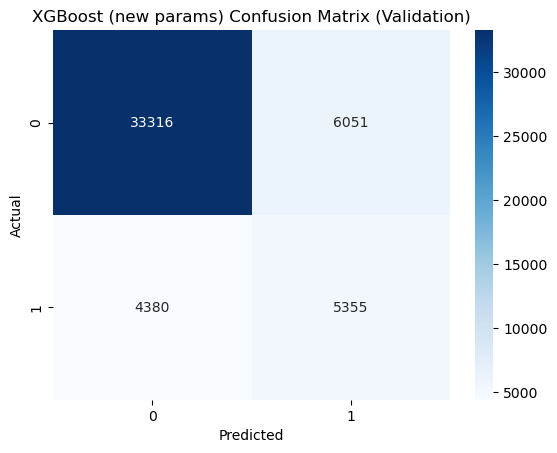

In [50]:
# Recompute class imbalance weight
pos = np.sum(y_train == 1)
neg = np.sum(y_train == 0)
scale_pos_weight = (neg / pos) if pos > 0 else 1.0

# Set new parameters here
xgb_model_new = XGBClassifier(
    n_estimators=400, # change at will
    learning_rate=0.05, # change at will
    max_depth=8, # change at will
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    min_child_weight=1,
    gamma=0.0,
    random_state=5059,
    n_jobs=-1,
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight
)

# Fit on the SAME training set
xgb_model_new.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

# Print the diagnostics (report, ROC/PR stats, confusion matrix, store curves)
evaluate_model(xgb_model_new, X_train, y_train, X_val, y_val, "XGBoost (new params)")

<h3>The preferred model setup is the same as the original. (which was already obtained through tinkering, so no massive surprise). We prefer the 200 estimators to 400 because it prioritises recall, which is central to the task.</h3>

<br>

<h3>We now tune the threshold to improve performance for this task.</h3>

Best F1 threshold: 0.55


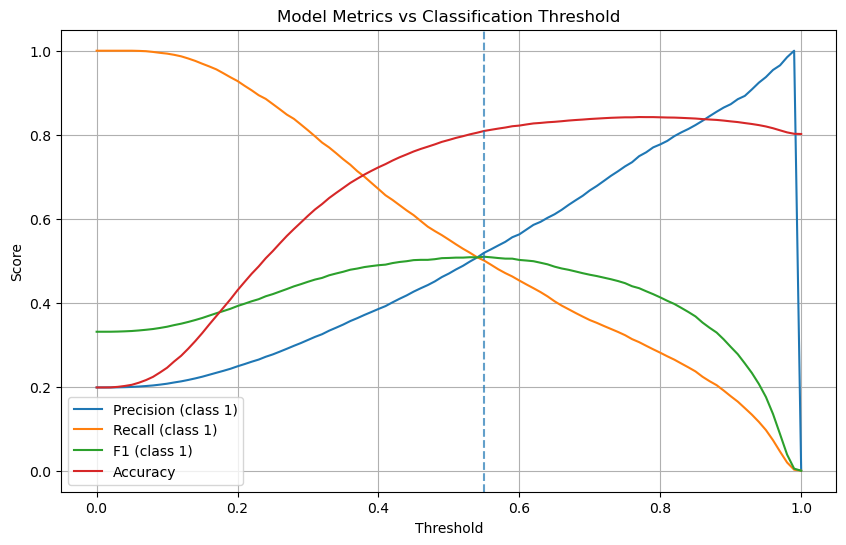

In [51]:
# Get predicted probabilities for class 1
y_proba = xgb_model_new.predict_proba(X_val)[:, 1]

# Define thresholds
thresholds = np.linspace(0, 1, 101)

precision_list = []
recall_list = []
f1_list = []
accuracy_list = []

for t in thresholds:
    y_pred = (y_proba >= t).astype(int)
    
    precision_list.append(precision_score(y_val, y_pred, zero_division=0))
    recall_list.append(recall_score(y_val, y_pred, zero_division=0))
    f1_list.append(f1_score(y_val, y_pred, zero_division=0))
    accuracy_list.append(accuracy_score(y_val, y_pred))

# Plot
plt.figure(figsize=(10, 6))

plt.plot(thresholds, precision_list, label="Precision (class 1)")
plt.plot(thresholds, recall_list, label="Recall (class 1)")
plt.plot(thresholds, f1_list, label="F1 (class 1)")
plt.plot(thresholds, accuracy_list, label="Accuracy")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Model Metrics vs Classification Threshold")
plt.legend()
plt.grid(True)

best_idx = np.argmax(f1_list)
best_threshold = thresholds[best_idx]

plt.axvline(best_threshold, linestyle="--", alpha=0.7)
print("Best F1 threshold:", best_threshold)

plt.show()

              precision    recall  f1-score   support

           0       0.88      0.86      0.87     39367
           1       0.49      0.53      0.51      9735

    accuracy                           0.80     49102
   macro avg       0.68      0.70      0.69     49102
weighted avg       0.80      0.80      0.80     49102



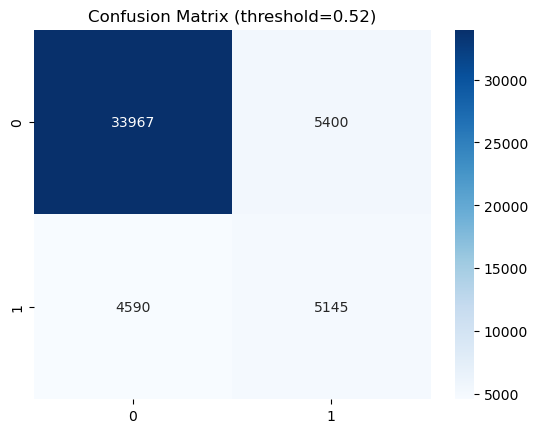

In [52]:
XGB_threshold = 0.52 # Change to test different values
preds = (y_proba > XGB_threshold).astype(int)

print(classification_report(y_val, preds))

cm = confusion_matrix(y_val, preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Confusion Matrix (threshold={XGB_threshold})')
plt.show()


<h2>Try random forest</h2>


==================== Random Forest (new params) ====================
Train classification report:
              precision    recall  f1-score   support

           0     0.8919    0.8233    0.8562    173943
           1     0.5518    0.6855    0.6115     55199

    accuracy                         0.7901    229142
   macro avg     0.7219    0.7544    0.7339    229142
weighted avg     0.8100    0.7901    0.7973    229142

Validation classification report:
              precision    recall  f1-score   support

           0     0.8802    0.8596    0.8698     39367
           1     0.4813    0.5269    0.5030      9735

    accuracy                         0.7936     49102
   macro avg     0.6807    0.6932    0.6864     49102
weighted avg     0.8011    0.7936    0.7971     49102

Train ROC-AUC: 0.8462 | Train AP (PR-AUC): 0.6889
Val   ROC-AUC: 0.7708 | Val   AP (PR-AUC): 0.5339


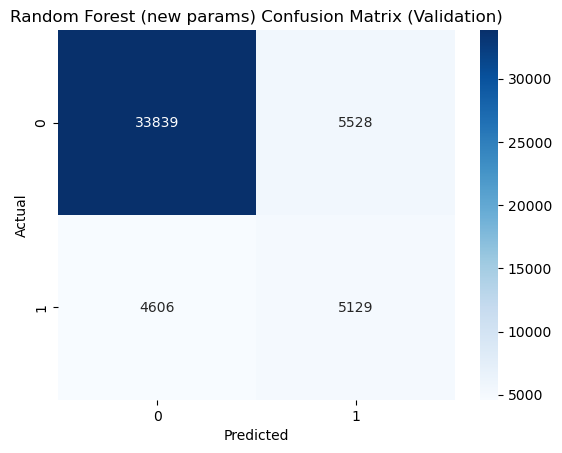

In [53]:
# Set new parameters here
rf_model_new = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_leaf=5,
    random_state=5059,
    class_weight='balanced',
    n_jobs=-1
)

# Fit on the SAME training set
rf_model_new.fit(
    X_train, y_train,
)

# Print the diagnostics (report, ROC/PR stats, confusion matrix, store curves)
evaluate_model(rf_model_new, X_train, y_train, X_val, y_val, "Random Forest (new params)")

Best F1 threshold: 0.53


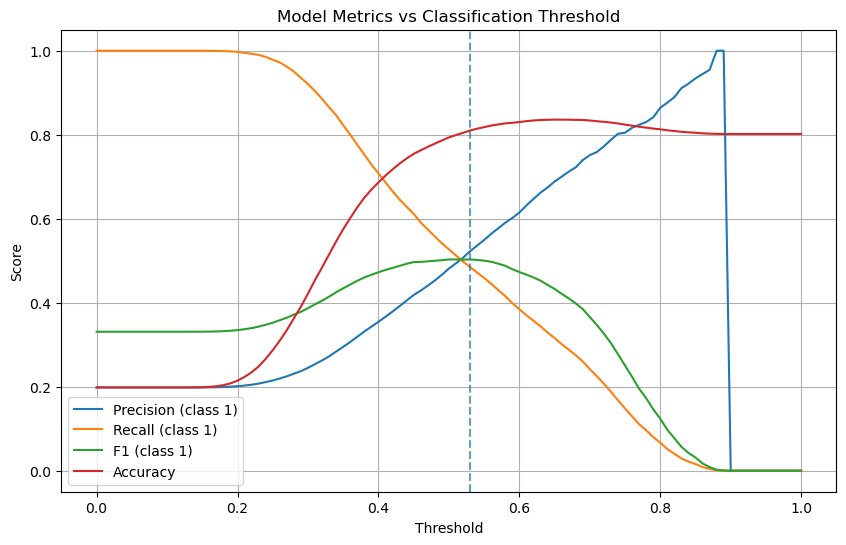

In [54]:
# Get predicted probabilities for class 1
y_proba = rf_model_new.predict_proba(X_val)[:, 1]

# Define thresholds
thresholds = np.linspace(0, 1, 101)

precision_list = []
recall_list = []
f1_list = []
accuracy_list = []

for t in thresholds:
    y_pred = (y_proba >= t).astype(int)
    
    precision_list.append(precision_score(y_val, y_pred, zero_division=0))
    recall_list.append(recall_score(y_val, y_pred, zero_division=0))
    f1_list.append(f1_score(y_val, y_pred, zero_division=0))
    accuracy_list.append(accuracy_score(y_val, y_pred))

# Plot
plt.figure(figsize=(10, 6))

plt.plot(thresholds, precision_list, label="Precision (class 1)")
plt.plot(thresholds, recall_list, label="Recall (class 1)")
plt.plot(thresholds, f1_list, label="F1 (class 1)")
plt.plot(thresholds, accuracy_list, label="Accuracy")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Model Metrics vs Classification Threshold")
plt.legend()
plt.grid(True)

best_idx = np.argmax(f1_list)
best_threshold = thresholds[best_idx]

plt.axvline(best_threshold, linestyle="--", alpha=0.7)
print("Best F1 threshold:", best_threshold)

plt.show()

              precision    recall  f1-score   support

           0       0.88      0.88      0.88     39367
           1       0.51      0.50      0.50      9735

    accuracy                           0.80     49102
   macro avg       0.69      0.69      0.69     49102
weighted avg       0.80      0.80      0.80     49102



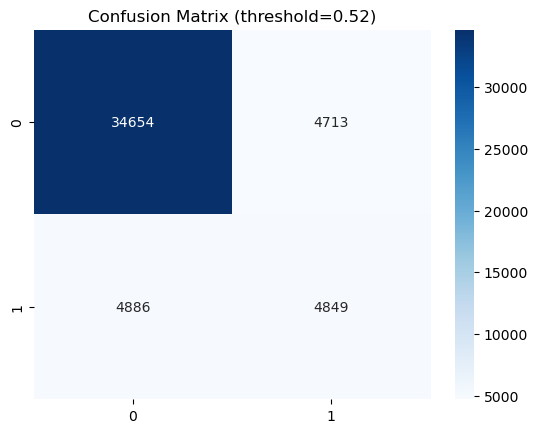

In [55]:
rf_threshold = 0.52 # Change to test different values
preds = (y_proba > rf_threshold).astype(int)

print(classification_report(y_val, preds))

cm = confusion_matrix(y_val, preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Confusion Matrix (threshold={rf_threshold})')
plt.show()